# **Supplementary Analyses For The Discover Artificial Intelligence Manuscript**

Computationally efficient AI models for pneumonia detection in low-resource settings.

Each section below is an independent cell: it imports what it needs, reads its inputs from Google Drive by path, and prints its results. No cell depends on another or on an earlier notebook. Run order is the order of the sections; the figure cells in sections 6 and 7 need the mean times printed by section 5.

| Section | Purpose | Manuscript item |
|---|---|---|
| 1 | Saved-file size audit | Tables 4, 5, 6 (sizes) |
| 2 | NIH distilled student evaluation on the current test folder | Table 6 |
| 3 | FP32 TensorFlow Lite baseline, 14-label model | Table 7 |
| 4 | FP32 TensorFlow Lite baseline, Nuclear Ensemble | Table 7 |
| 5 | Grad-CAM benchmark: eager and compiled implementations | Grad-CAM results text (first run) |
| 6 | Grad-CAM figure, EfficientNetB4 (NIH) | Fig. 5 |
| 7 | Grad-CAM figure, Xception (Mendeley) | Fig. 5 |
| 8 | Model optimisation figure | Fig. 3 |
| Further cells | Grad-CAM target layer; eager, compiled and 128 x 128 Grad-CAM | Table 9 |
| | TensorFlow Lite timing at explicit thread counts | Appendix Table A5 |
| | TensorFlow Lite timing with and without XNNPACK | Appendix Table A6 |
| | Parameters and multiply-accumulate operations | Table 8 |

## **1. Saved-file size audit**


In [ ]:
# =============================================================================
# Saved-file size audit
# -----------------------------------------------------------------------------
# Reports, for each model file, the size on disk and the size of its contents,
# separating the network weights from other stored state (optimiser variables).
# Files are opened as archives; no model is built or loaded.
# Sizes are in MB (1 MB = 1024 x 1024 bytes), as in the earlier size tables.
# =============================================================================
import io
import os
import zipfile

import h5py

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

MB = 1024 ** 2

MEND = '/content/drive/MyDrive/chest_xray'
NIH = '/content/drive/MyDrive/NIH_models'
ML = '/content/drive/MyDrive/Multi_Label_NIH_Models'

FILES = [
    ('Mendeley | ResNet50 (ensemble member)',     f'{MEND}/base_model_0.keras'),
    ('Mendeley | DenseNet121 (ensemble member)',  f'{MEND}/base_model_1.keras'),
    ('Mendeley | InceptionV3 (ensemble member)',  f'{MEND}/base_model_2.keras'),
    ('Mendeley | Xception (ensemble member)',     f'{MEND}/base_model_3.keras'),
    ('Mendeley | MobileNetV2 (ensemble member)',  f'{MEND}/base_model_4.keras'),
    ('Mendeley | Meta-learner',                   f'{MEND}/nuclear_ensemble_meta_learner.keras'),
    ('NIH | EfficientNetB4, epoch 15 (original)', f'{NIH}/Results/EffNetB4_epoch_15.h5'),
    ('NIH | MobileNetV2 student',                 f'{NIH}/Knowledge_Distillation/student_model_final.keras'),
    ('14-label | EfficientNetB4 V6 (original)',
     f'{ML}/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'),
    ('14-label | V6 dynamic-range TFLite',
     f'{ML}/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'),
] + [
    (f'Mendeley | ensemble member {i}, full-integer TFLite',
     f'{MEND}/PTQ_Quantized_Ensemble/base_model_{i}_int8.tflite')
    for i in range(5)
]

OPTIMISER_GROUPS = {'optimizer', 'optimizer_weights'}


def dataset_bytes(node):
    """Uncompressed size in bytes of all datasets below an HDF5 node."""
    if isinstance(node, h5py.Dataset):
        return node.size * node.dtype.itemsize
    total = 0

    def visit(_name, obj):
        nonlocal total
        if isinstance(obj, h5py.Dataset):
            total += obj.size * obj.dtype.itemsize

    node.visititems(visit)
    return total


def split_h5(h5file):
    """Return (weight bytes, optimiser bytes) for an open HDF5 weights file."""
    weights = optimiser = 0
    for key in h5file.keys():
        n = dataset_bytes(h5file[key])
        if key in OPTIMISER_GROUPS:
            optimiser += n
        else:
            weights += n
    return weights, optimiser


def audit(path):
    disk = os.path.getsize(path)
    ext = os.path.splitext(path)[1].lower()
    if ext == '.keras':
        with zipfile.ZipFile(path) as z:
            members = {i.filename: i.file_size for i in z.infolist()}
            with h5py.File(io.BytesIO(z.read('model.weights.h5')), 'r') as h:
                weights, optimiser = split_h5(h)
        other = sum(v for k, v in members.items() if k != 'model.weights.h5')
        return disk, weights, optimiser, other
    if ext in ('.h5', '.hdf5'):
        with h5py.File(path, 'r') as h:
            weights, optimiser = split_h5(h)
        return disk, weights, optimiser, 0
    return disk, None, None, None          # TensorFlow Lite: file size only


header = f"{'File':<52}{'On disk':>9}{'Weights':>9}{'Optimiser':>11}{'Config':>8}{'Weights/disk':>14}"
print(header)
print('-' * len(header))
for label, path in FILES:
    if not os.path.exists(path):
        print(f'{label:<52}  not found: {path}')
        continue
    disk, weights, optimiser, other = audit(path)
    if weights is None:
        print(f'{label:<52}{disk / MB:>9.2f}{"-":>9}{"-":>11}{"-":>8}{"-":>14}')
    else:
        print(f'{label:<52}{disk / MB:>9.2f}{weights / MB:>9.2f}'
              f'{optimiser / MB:>11.2f}{other / MB:>8.2f}{weights / disk:>14.2f}')


Mounted at /content/drive
File                                                  On disk  Weights  Optimiser  Config  Weights/disk
-------------------------------------------------------------------------------------------------------
Mendeley | ResNet50 (ensemble member)                   92.61    91.98       0.00    0.16          0.99
Mendeley | DenseNet121 (ensemble member)                29.29    27.85       0.00    0.39          0.95
Mendeley | InceptionV3 (ensemble member)                86.22    85.17       0.00    0.29          0.99
Mendeley | Xception (ensemble member)                   82.06    81.58       0.00    0.13          0.99
Mendeley | MobileNetV2 (ensemble member)                10.42     9.87       0.00    0.15          0.95
Mendeley | Meta-learner                                  0.15     0.04       0.07    0.01          0.26
NIH | EfficientNetB4, epoch 15 (original)              208.32    69.17     137.39    0.00          0.33
NIH | MobileNetV2 student             

## **2. NIH distilled student: evaluation on the current test folder**
**Returns:** confusion matrix, accuracy, sensitivity, specificity, balanced accuracy and AUROC of the saved MobileNetV2 student on the 1,784-image NIH test set.

In [ ]:
# =============================================================================
# NIH distilled student (MobileNetV2): evaluation on the current test folder
# -----------------------------------------------------------------------------
# Evaluates the saved student on the NIH binary test set (1,272 normal and
# 512 pneumonia images) at a decision threshold of 0.5 and reports accuracy,
# sensitivity, specificity, balanced accuracy and AUROC.
# The student takes raw 0-255 RGB input at 224 x 224 (rescaling and
# MobileNetV2 pre-processing are part of the saved graph).
# =============================================================================
import os

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, roc_auc_score

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

STUDENT_PATH = '/content/drive/MyDrive/NIH_models/Knowledge_Distillation/student_model_final.keras'
TEST_DIR = '/content/drive/MyDrive/NIH_processed/test'
CLASS_NAMES = ['normal', 'pneumonia']
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
THRESHOLD = 0.5

student = tf.keras.models.load_model(STUDENT_PATH, compile=False)
print(f'Student file: {os.path.getsize(STUDENT_PATH) / 1024 ** 2:.2f} MB; '
      f'input {student.input_shape}; parameters {student.count_params():,}')

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, labels='inferred', label_mode='binary', class_names=CLASS_NAMES,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

scores, labels = [], []
for images, y in test_ds:
    scores.append(student.predict(images, verbose=0).ravel())
    labels.append(y.numpy().ravel())
scores = np.concatenate(scores)
labels = np.concatenate(labels).astype(int)
pred = (scores > THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(labels, pred).ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f'\nTest images: {len(labels)} (normal {int((labels == 0).sum())}, '
      f'pneumonia {int((labels == 1).sum())})')
print(f'Confusion matrix  TN {tn}  FP {fp}  FN {fn}  TP {tp}')
print(f'Accuracy           {(tn + tp) / len(labels) * 100:6.2f} %')
print(f'Sensitivity        {sensitivity * 100:6.2f} %')
print(f'Specificity        {specificity * 100:6.2f} %')
print(f'Balanced accuracy  {(sensitivity + specificity) / 2 * 100:6.2f} %')
print(f'AUROC              {roc_auc_score(labels, scores) * 100:6.2f} %')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Student file: 9.80 MB; input (None, 224, 224, 3); parameters 2,422,081
Found 1784 files belonging to 2 classes.

Test images: 1784 (normal 1272, pneumonia 512)
Confusion matrix  TN 928  FP 344  FN 182  TP 330
Accuracy            70.52 %
Sensitivity         64.45 %
Specificity         72.96 %
Balanced accuracy   68.70 %
AUROC               74.47 %


## **3. 14-label EfficientNetB4 (V6): FP32 TensorFlow Lite baseline and timing**

**Returns:** FP32 file size, agreement of the converted file with the Keras model, and inference time of the FP32 and dynamic-range files measured in the same session. The first run builds EfficientNetB4 and converts it, which takes several minutes.

In [ ]:
# =============================================================================
# 14-label EfficientNetB4 (V6): FP32 TensorFlow Lite baseline and timing
# -----------------------------------------------------------------------------
# 1. Rebuilds the V6 architecture and loads the trained weights.
# 2. Converts the model to an unquantised (FP32) TensorFlow Lite file.
# 3. Checks the converted file against the Keras model on the timing images.
# 4. Times the FP32 file and the dynamic-range file in the same session,
#    alternating between them image by image.
# Timing protocol as in the earlier deployment notebooks: batch size 1, one
# warm-up call, 50 images, interpreter defaults, times multiplied by
# (host clock / 1.5 GHz). Image loading and pre-processing are not timed.
# Images that cannot be read from Drive after three attempts are skipped and
# the next image of the test half is used instead.
# =============================================================================
import os
import time

import numpy as np
import pandas as pd
import psutil
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import (Add, Concatenate, Conv2D, Dense, Dropout,
                                     GlobalAveragePooling2D, Input, Lambda,
                                     Multiply, Reshape, Rescaling)
from tensorflow.keras.models import Model

# try:
#     from google.colab import drive
#     drive.mount('/content/drive')
# except ImportError:
#     pass

ML = '/content/drive/MyDrive/Multi_Label_NIH_Models'
WEIGHTS_PATH = f'{ML}/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'
DYNAMIC_RANGE_PATH = f'{ML}/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'
FP32_PATH = f'{ML}/EfficientNetB4_V6_Quantized/v6_fp32.tflite'
IMAGE_DIR = '/content/drive/MyDrive/NIH_ChestXray/images_extracted/images'
VAL_XLSX = '/content/drive/MyDrive/Multi_Label_Classification/val_original.xlsx'
N_LABELS = 14
IMG_SIZE = (224, 224)
N_IMAGES = 50
PI_GHZ = 1.5

try:
    host_ghz = psutil.cpu_freq().current / 1000.0
    freq_note = ''
except Exception:
    host_ghz, freq_note = 2.2, ' (clock not reported; 2.2 GHz assumed)'
clock_factor = host_ghz / PI_GHZ
print(f'Host: {host_ghz * 1000:.0f} MHz, {psutil.cpu_count(logical=False)} physical / '
      f'{psutil.cpu_count(logical=True)} logical cores, '
      f'{psutil.virtual_memory().total / 1024 ** 3:.2f} GB; clock factor {clock_factor:.2f}{freq_note}')


# architecture
def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)
    max_pool = Lambda(lambda t: tf.reduce_max(t, axis=[1, 2]),
                      output_shape=lambda s: (s[0], s[-1]))(x)
    dense1 = Dense(channels // ratio, activation='relu')
    dense2 = Dense(channels, activation='sigmoid')
    attention = Add()([dense2(dense1(avg_pool)), dense2(dense1(max_pool))])
    attention = Reshape((1, 1, channels))(attention)
    return Multiply()([x, attention])


def spatial_attention(x):
    pooled_shape = lambda s: (s[0], s[1], s[2], 1)
    avg_pool = Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
                      output_shape=pooled_shape)(x)
    max_pool = Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
                      output_shape=pooled_shape)(x)
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(
        Concatenate(axis=-1)([avg_pool, max_pool]))
    return Multiply()([x, attention])


def build_v6():
    inputs = Input(shape=(*IMG_SIZE, 3))
    x = Rescaling(1.0 / 255)(inputs)
    x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)
    base = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)
    taps = ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']
    pooled = []
    for name in taps:
        feature = spatial_attention(channel_attention(base.get_layer(name).output))
        pooled.append(GlobalAveragePooling2D()(feature))
    x = Concatenate()(pooled)
    l2 = tf.keras.regularizers.l2(0.001)
    x = Dense(512, activation='relu', kernel_regularizer=l2)(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation='relu', kernel_regularizer=l2)(x)
    x = Dropout(0.3)(x)
    return Model(inputs, Dense(N_LABELS, activation='sigmoid')(x))


model = build_v6()
model.load_weights(WEIGHTS_PATH)
print(f'V6 rebuilt: {model.count_params():,} parameters')

#  FP32 conversion (an existing FP32 file is reused)
if os.path.exists(FP32_PATH) and os.path.getsize(FP32_PATH) > 0:
    print('Existing FP32 file found; conversion skipped.')
else:
    fp32_bytes = tf.lite.TFLiteConverter.from_keras_model(model).convert()   # no optimisation
    with open(FP32_PATH, 'wb') as f:
        f.write(fp32_bytes)
print(f'FP32 TFLite: {os.path.getsize(FP32_PATH) / 1024 ** 2:.2f} MB  ->  {FP32_PATH}')
print(f'Dynamic-range TFLite: {os.path.getsize(DYNAMIC_RANGE_PATH) / 1024 ** 2:.2f} MB')

# timing images: first N_IMAGES readable images of the test half
table = pd.read_excel(VAL_XLSX)
_, test_half = train_test_split(table, test_size=0.5, random_state=123)


def load_image(path, attempts=3):
    for k in range(attempts):
        try:
            raw = tf.io.read_file(path)
            img = tf.image.decode_png(raw, channels=3)
            return tf.image.resize(img, IMG_SIZE).numpy().astype(np.float32)[None]
        except tf.errors.OpError:
            time.sleep(2)
    return None


images, skipped = [], []
for name in test_half['Image Index']:
    img = load_image(os.path.join(IMAGE_DIR, name))
    if img is None:
        skipped.append(name)
        continue
    images.append(img)
    if len(images) == N_IMAGES:
        break
print(f'Images loaded: {len(images)}; skipped (unreadable): {skipped if skipped else "none"}')


def make_runner(model_path):
    interp = tf.lite.Interpreter(model_path=model_path)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

    def run(x):
        interp.set_tensor(inp['index'], x)
        interp.invoke()
        return interp.get_tensor(out['index'])[0]
    return run


run_fp32 = make_runner(FP32_PATH)
run_dyn = make_runner(DYNAMIC_RANGE_PATH)

#  conversion check
keras_out = model.predict(np.concatenate(images), verbose=0)
fp32_out = np.stack([run_fp32(x) for x in images])
dyn_out = np.stack([run_dyn(x) for x in images])
print(f'\nMax |Keras - FP32 TFLite|          : {np.abs(keras_out - fp32_out).max():.2e}')
print(f'Mean |FP32 TFLite - dynamic range| : {np.abs(fp32_out - dyn_out).mean():.4f}')

#  timing
run_fp32(images[0]); run_dyn(images[0])                          # warm-up
t_fp32, t_dyn = [], []
for i, x in enumerate(images):
    order = [('fp32', run_fp32), ('dyn', run_dyn)]
    if i % 2:
        order.reverse()
    for tag, fn in order:
        t0 = time.perf_counter()
        fn(x)
        ms = (time.perf_counter() - t0) * 1000 * clock_factor
        (t_fp32 if tag == 'fp32' else t_dyn).append(ms)

print(f'\nImages timed: {len(images)}')
print(f'FP32 TFLite          : {np.mean(t_fp32):8.2f} +/- {np.std(t_fp32):.2f} ms')
print(f'Dynamic-range TFLite : {np.mean(t_dyn):8.2f} +/- {np.std(t_dyn):.2f} ms')
print(f'Speed-up (FP32 / dynamic range): {np.mean(t_fp32) / np.mean(t_dyn):.2f}x')

Host: 2200 MHz, 1 physical / 2 logical cores, 12.67 GB; clock factor 1.47
V6 rebuilt: 20,097,346 parameters
Existing FP32 file found; conversion skipped.
FP32 TFLite: 76.14 MB  ->  /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_fp32.tflite
Dynamic-range TFLite: 20.53 MB
Images loaded: 50; skipped (unreadable): none


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



Max |Keras - FP32 TFLite|          : 2.56e-06
Mean |FP32 TFLite - dynamic range| : 0.0340

Images timed: 50
FP32 TFLite          :   141.27 +/- 27.07 ms
Dynamic-range TFLite :   209.02 +/- 42.19 ms
Speed-up (FP32 / dynamic range): 0.68x


## **4. Nuclear Ensemble: FP32 TensorFlow Lite baseline and timing**

**Returns:** FP32 file sizes of the five members and the meta-learner, agreement of each converted member with its Keras model, and pipeline inference time with FP32 and full-integer files measured in the same session.

In [ ]:
# =============================================================================
# Nuclear Ensemble (Mendeley): FP32 TensorFlow Lite baseline and timing
# -----------------------------------------------------------------------------
# 1. Converts the five trained members and the meta-learner to unquantised
#    (FP32) TensorFlow Lite files.
# 2. Checks each converted member against its Keras model.
# 3. Times the complete five-member pipeline (per-member resize and
#    pre-processing, inference, weighted average) with the FP32 files and
#    with the full-integer files, in the same session and alternating
#    image by image.
# Protocol as in the original deployment notebooks: batch size 1, one warm-up,
# 50 images (25 per class), interpreter defaults, times multiplied by
# (host clock / 1.5 GHz). The meta-learner is not part of the timed pipeline.
# =============================================================================
import glob
import os
import time

import numpy as np
import psutil
import tensorflow as tf
from PIL import Image

# try:
#     from google.colab import drive
#     drive.mount('/content/drive')
# except ImportError:
#     pass

BASE = '/content/drive/MyDrive/chest_xray'
TEST_DIR = f'{BASE}/test'
INT8_DIR = f'{BASE}/PTQ_Quantized_Ensemble'
FP32_DIR = f'{BASE}/FP32_TFLite_Ensemble'
os.makedirs(FP32_DIR, exist_ok=True)
PI_GHZ = 1.5

# Member name and pre-processing function. The input size of each member is
# read from the model itself.
MEMBERS = [
    ('ResNet50',    tf.keras.applications.resnet.preprocess_input),
    ('DenseNet121', tf.keras.applications.densenet.preprocess_input),
    ('InceptionV3', tf.keras.applications.inception_v3.preprocess_input),
    ('Xception',    tf.keras.applications.xception.preprocess_input),
    ('MobileNetV2', tf.keras.applications.mobilenet_v2.preprocess_input),
]

try:
    host_ghz = psutil.cpu_freq().current / 1000.0
    freq_note = ''
except Exception:
    host_ghz, freq_note = 2.2, ' (clock not reported; 2.2 GHz assumed)'
clock_factor = host_ghz / PI_GHZ
print(f'Host: {host_ghz * 1000:.0f} MHz, {psutil.cpu_count(logical=False)} physical / '
      f'{psutil.cpu_count(logical=True)} logical cores, '
      f'{psutil.virtual_memory().total / 1024 ** 3:.2f} GB; clock factor {clock_factor:.2f}{freq_note}')

#  timing images
image_paths = []
for cls in ('NORMAL', 'PNEUMONIA'):
    folder = os.path.join(TEST_DIR, cls)
    found = glob.glob(os.path.join(folder, '*.jpeg'))[:25] + glob.glob(os.path.join(folder, '*.jpg'))[:25]
    image_paths.extend(found)
print(f'Timing images: {len(image_paths)}')


def prepare(path, size, preprocess):
    arr = np.array(Image.open(path).convert('RGB').resize(size), dtype=np.float32)
    return preprocess(arr[None]).astype(np.float32)


#  FP32 conversion and check
fp32_paths, fp32_total = [], 0
for i, (name, preprocess) in enumerate(MEMBERS):
    keras_model = tf.keras.models.load_model(f'{BASE}/base_model_{i}.keras', compile=False)
    size = tuple(keras_model.input_shape[1:3])
    tflite_bytes = tf.lite.TFLiteConverter.from_keras_model(keras_model).convert()
    path = f'{FP32_DIR}/base_model_{i}_fp32.tflite'
    with open(path, 'wb') as f:
        f.write(tflite_bytes)
    fp32_paths.append(path)
    fp32_total += len(tflite_bytes)

    interp = tf.lite.Interpreter(model_path=path)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    worst = 0.0
    for p in image_paths[:10]:
        x = prepare(p, size, preprocess)
        interp.set_tensor(inp['index'], x)
        interp.invoke()
        worst = max(worst, float(np.abs(interp.get_tensor(out['index']) - keras_model(x).numpy()).max()))
    print(f'{name:<12} input {size[0]}x{size[1]}  FP32 TFLite {len(tflite_bytes) / 1024 ** 2:7.2f} MB   '
          f'max |Keras - TFLite| over 10 images: {worst:.2e}')
    del keras_model

meta = tf.keras.models.load_model(f'{BASE}/nuclear_ensemble_meta_learner.keras', compile=False)
meta_bytes = tf.lite.TFLiteConverter.from_keras_model(meta).convert()
with open(f'{FP32_DIR}/meta_learner_fp32.tflite', 'wb') as f:
    f.write(meta_bytes)
print(f'Meta-learner FP32 TFLite {len(meta_bytes) / 1024 ** 2:.3f} MB')
print(f'\nFive members, FP32 TFLite: {fp32_total / 1024 ** 2:.2f} MB '
      f'(with meta-learner {(fp32_total + len(meta_bytes)) / 1024 ** 2:.2f} MB)')

int8_paths = [f'{INT8_DIR}/base_model_{i}_int8.tflite' for i in range(len(MEMBERS))]
print(f'Five members, full-integer TFLite: '
      f'{sum(os.path.getsize(p) for p in int8_paths) / 1024 ** 2:.2f} MB')


#  pipeline timing
def load_pipeline(paths):
    runners = []
    for p in paths:
        interp = tf.lite.Interpreter(model_path=p)
        interp.allocate_tensors()
        runners.append((interp, interp.get_input_details()[0], interp.get_output_details()[0]))
    return runners


def run_pipeline(runners, path):
    probs = []
    for (interp, inp, out), (_, preprocess) in zip(runners, MEMBERS):
        size = (int(inp['shape'][2]), int(inp['shape'][1]))
        interp.set_tensor(inp['index'], prepare(path, size, preprocess))
        interp.invoke()
        probs.append(interp.get_tensor(out['index']))
    return np.mean(probs, axis=0)           # equal weights; weights do not affect timing


fp32_runners = load_pipeline(fp32_paths)
int8_runners = load_pipeline(int8_paths)
run_pipeline(fp32_runners, image_paths[0])
run_pipeline(int8_runners, image_paths[0])

t_fp32, t_int8, agree = [], [], 0
for i, path in enumerate(image_paths):
    order = [('fp32', fp32_runners), ('int8', int8_runners)]
    if i % 2:
        order.reverse()
    preds = {}
    for tag, runners in order:
        t0 = time.perf_counter()
        preds[tag] = run_pipeline(runners, path)
        ms = (time.perf_counter() - t0) * 1000 * clock_factor
        (t_fp32 if tag == 'fp32' else t_int8).append(ms)
    agree += int(np.argmax(preds['fp32']) == np.argmax(preds['int8']))

print(f'\nImages timed: {len(image_paths)}')
print(f'Five-member pipeline, FP32 TFLite         : {np.mean(t_fp32):8.2f} +/- {np.std(t_fp32):.2f} ms')
print(f'Five-member pipeline, full-integer TFLite : {np.mean(t_int8):8.2f} +/- {np.std(t_int8):.2f} ms')
print(f'Speed-up (FP32 / full-integer): {np.mean(t_fp32) / np.mean(t_int8):.2f}x')
print(f'Same predicted class, FP32 against full-integer: {agree} of {len(image_paths)} images')


Host: 2200 MHz, 1 physical / 2 logical cores, 12.67 GB; clock factor 1.47
Timing images: 50
Saved artifact at '/tmp/tmpm7145ajm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132256806760528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806758416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806758992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806759376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806756304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806758800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806758608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806756880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806757072: TensorSpec(shape=(), dtype=tf.resource, name=N

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


ResNet50     input 224x224  FP32 TFLite   91.62 MB   max |Keras - TFLite| over 10 images: 1.67e-06
Saved artifact at '/tmp/tmpxw1a48q2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132256502625680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748549136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748539728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256806760336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748539536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748540880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748538192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748540304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748547600: TensorSpec(shape=(), dtype=tf.resourc

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


DenseNet121  input 224x224  FP32 TFLite   27.62 MB   max |Keras - TFLite| over 10 images: 2.92e-06
Saved artifact at '/tmp/tmpmhs6v2v8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 299, 299, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132256756707216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256508295888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256508296272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256756705872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256508296848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256508297040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256508295312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256508296656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256511171984: TensorSpec(shape=(), dtype=tf.resourc

...

Xception     input 299x299  FP32 TFLite   81.33 MB   max |Keras - TFLite| over 10 images: 8.34e-07
Saved artifact at '/tmp/tmpv8wccvit'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132256748545872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748550288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748544336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748541072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748552016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748545680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256502612240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256502613392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256748543184: TensorSpec(shape=(), dtype=tf.resourc

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_4']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


MobileNetV2  input 224x224  FP32 TFLite    9.71 MB   max |Keras - TFLite| over 10 images: 2.82e-06
Saved artifact at '/tmp/tmpi00t3ezx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 5, 2), dtype=tf.float32, name='input_layer_5')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132256489022544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256489023120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256489024464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256489022160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256489022928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132256489022736: TensorSpec(shape=(), dtype=tf.resource, name=None)
Meta-learner FP32 TFLite 0.040 MB

Five members, FP32 TFLite: 295.40 MB (with meta-learner 295.44 MB)
Five members, full-integer TFLite: 77.17 MB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



Images timed: 50
Five-member pipeline, FP32 TFLite         :  1591.36 +/- 435.70 ms
Five-member pipeline, full-integer TFLite :  1655.27 +/- 328.65 ms
Speed-up (FP32 / full-integer): 0.96x
Same predicted class, FP32 against full-integer: 50 of 50 images


## **5. Grad-CAM benchmark: standard (eager) and compiled implementations**

**Returns:** for the Xception and EfficientNetB4 models, mean ± SD time per image for eager Grad-CAM and for the compiled implementation at native input size, the speed-up, and the agreement of the maps.

In [ ]:
# =============================================================================
# Grad-CAM benchmark: standard (eager) against compiled implementation
# -----------------------------------------------------------------------------
# For each model, 50 test images (25 per class, seed 42) are explained three
# ways:
#   eager      Grad-CAM executed operation by operation (standard)
#   compiled   the same computation wrapped in tf.function, native input size
#   compiled at 128 x 128, input resized before the call (reference only)
# Reported: mean +/- SD time per image, speed-up over eager, and agreement of
# each variant with the eager map (Pearson correlation and IoU at 0.5 on
# min-max normalised maps).
# Times cover the Grad-CAM computation only (image loading and pre-processing
# excluded) and are multiplied by (host clock / 1.5 GHz), as in the earlier
# deployment notebooks.
# =============================================================================
import glob
import os
import random
import time

import numpy as np
import psutil
import tensorflow as tf
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

os.environ['TF_NUM_INTRAOP_THREADS'] = '4'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'

PI_GHZ = 1.5
SEED = 42
N_PER_CLASS = 25
SMALL = (128, 128)

CONFIGS = {
    'Xception (Mendeley)': dict(
        model_path='/content/drive/MyDrive/chest_xray/base_model_3.keras',
        test_dir='/content/drive/MyDrive/chest_xray/test',
        classes=['NORMAL', 'PNEUMONIA'],
        size=(299, 299),
        preprocess=tf.keras.applications.xception.preprocess_input),
    'EfficientNetB4 (NIH)': dict(
        model_path='/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5',
        test_dir='/content/drive/MyDrive/NIH_processed/test',
        classes=['normal', 'pneumonia'],
        size=(224, 224),
        preprocess=tf.keras.applications.efficientnet.preprocess_input),
}

try:
    host_ghz = psutil.cpu_freq().current / 1000.0
    freq_note = ''
except Exception:
    host_ghz, freq_note = 2.2, ' (clock not reported; 2.2 GHz assumed)'
clock_factor = host_ghz / PI_GHZ
print(f'Host: {host_ghz * 1000:.0f} MHz, {psutil.cpu_count(logical=False)} physical / '
      f'{psutil.cpu_count(logical=True)} logical cores, '
      f'{psutil.virtual_memory().total / 1024 ** 3:.2f} GB; clock factor {clock_factor:.2f}{freq_note}')


def select_images(test_dir, classes):
    rng = random.Random(SEED)
    chosen = []
    for cls in classes:
        folder = os.path.join(test_dir, cls)
        files = sorted(glob.glob(os.path.join(folder, '*.jpeg')) + glob.glob(os.path.join(folder, '*.jpg'))
                       + glob.glob(os.path.join(folder, '*.png')))
        rng.shuffle(files)
        chosen += files[:N_PER_CLASS]
    return chosen


def last_conv_name(model):
    for layer in reversed(model.layers):
        if 'conv' in layer.name.lower() and len(layer.output.shape) == 4:
            return layer.name
    raise ValueError('No convolutional layer found')


def normalise(heat):
    heat = np.asarray(heat, dtype=np.float64)
    span = heat.max() - heat.min()
    return (heat - heat.min()) / span if heat.max() > 0 and span > 0 else np.zeros_like(heat)


def correlation(a, b):
    a, b = a.ravel(), b.ravel()
    if a.std() < 1e-8 or b.std() < 1e-8:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])


def iou(a, b, thr=0.5):
    a, b = a >= thr, b >= thr
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


def run_benchmark(title, cfg):
    model = tf.keras.models.load_model(cfg['model_path'], compile=False)
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(last_conv_name(model)).output, model.output])
    softmax_head = len(model.output_shape) == 2 and model.output_shape[1] == 2
    target = cfg['size']

    def cam(x):
        with tf.GradientTape() as tape:
            tape.watch(x)
            conv, preds = grad_model(x)
            preds = tf.reshape(tf.cast(preds, tf.float32), [1, -1])
            score = preds[:, 1] if softmax_head else preds[:, 0]
        grads = tape.gradient(score, conv)
        weights = tf.reduce_mean(grads, axis=(0, 1, 2))
        heat = tf.nn.relu(tf.tensordot(conv[0], weights, axes=[[2], [0]]))
        return tf.image.resize(heat[..., tf.newaxis], target)[..., 0]

    cam_compiled = tf.function(cam)

    def load(path):
        img = Image.open(path).convert('RGB').resize(target)
        arr = np.array(img, dtype=np.float32)
        return tf.convert_to_tensor(cfg['preprocess'](arr[None]).astype(np.float32))

    paths = select_images(cfg['test_dir'], cfg['classes'])
    first = load(paths[0])
    first_small = tf.image.resize(first, SMALL, method='bilinear')
    cam(first); cam_compiled(first)                                      # warm-up and tracing
    try:                                                                 # fixed-input models reject 128 x 128
        cam_compiled(first_small)
        small_ok = True
    except ValueError as err:
        small_ok = False
        print(f'\n{title}: the 128 x 128 input is rejected by the model ({str(err).splitlines()[-1].strip()[:110]})')

    t = {'eager': [], 'compiled': [], 'small': []}
    r = {'compiled': [], 'small': []}
    u = {'compiled': [], 'small': []}
    for p in paths:
        x = load(p)
        x_small = tf.image.resize(x, SMALL, method='bilinear')

        t0 = time.perf_counter(); h_eager = cam(x)
        t['eager'].append((time.perf_counter() - t0) * clock_factor)
        t0 = time.perf_counter(); h_comp = cam_compiled(x)
        t['compiled'].append((time.perf_counter() - t0) * clock_factor)
        if small_ok:
            t0 = time.perf_counter(); h_small = cam_compiled(x_small)
            t['small'].append((time.perf_counter() - t0) * clock_factor)

        ref = normalise(h_eager.numpy())
        for key, h in (('compiled', h_comp), ('small', h_small if small_ok else None)):
            if h is None:
                continue
            h = normalise(h.numpy())
            r[key].append(correlation(ref, h))
            u[key].append(iou(ref, h))

    print(f'\n{title}: {len(paths)} images, input {target[0]}x{target[1]}')
    print(f"  eager                         {np.mean(t['eager']):7.3f} +/- {np.std(t['eager']):.3f} s")
    for key, label in (('compiled', 'compiled, native size'), ('small', 'compiled, 128 x 128 input')):
        if not t[key]:
            continue
        print(f"  {label:<30}{np.mean(t[key]):7.3f} +/- {np.std(t[key]):.3f} s   "
              f"speed-up {np.mean(t['eager']) / np.mean(t[key]):5.2f}x   "
              f"correlation {np.mean(r[key]):.3f}   IoU@0.5 {np.mean(u[key]):.3f}")
    tf.keras.backend.clear_session()


for title, cfg in CONFIGS.items():
    run_benchmark(title, cfg)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Host: 2200 MHz, 1 physical / 2 logical cores, 12.67 GB; clock factor 1.47

Xception (Mendeley): the 128 x 128 input is rejected by the model (ValueError: Input 0 with name 'input_layer_3' of layer 'functional_2' is incompatible with the layer: expected)

Xception (Mendeley): 50 images, input 299x299
  eager                           3.188 +/- 1.049 s
  compiled, native size           0.689 +/- 0.428 s   speed-up  4.63x   correlation 0.960   IoU@0.5 0.960

EfficientNetB4 (NIH): the 128 x 128 input is rejected by the model (ValueError: Input 0 with name 'input_layer' of layer 'functional' is incompatible with the layer: expected sha)

EfficientNetB4 (NIH): 50 images, input 224x224
  eager                           4.343 +/- 1.024 s
  compiled, native size           0.307 +/- 0.108 s   speed-up 14.16x   correlation 1.000   IoU@0.5 1.000


## **6. Grad-CAM figure: EfficientNetB4, NIH**

Set `MEAN_TIME_EAGER_S` and `MEAN_TIME_COMPILED_S` at the top of the cell to the EfficientNetB4 (NIH) means printed in section 5. **Returns:** `/content/gradcam_efficientnetb4_compiled.png`.

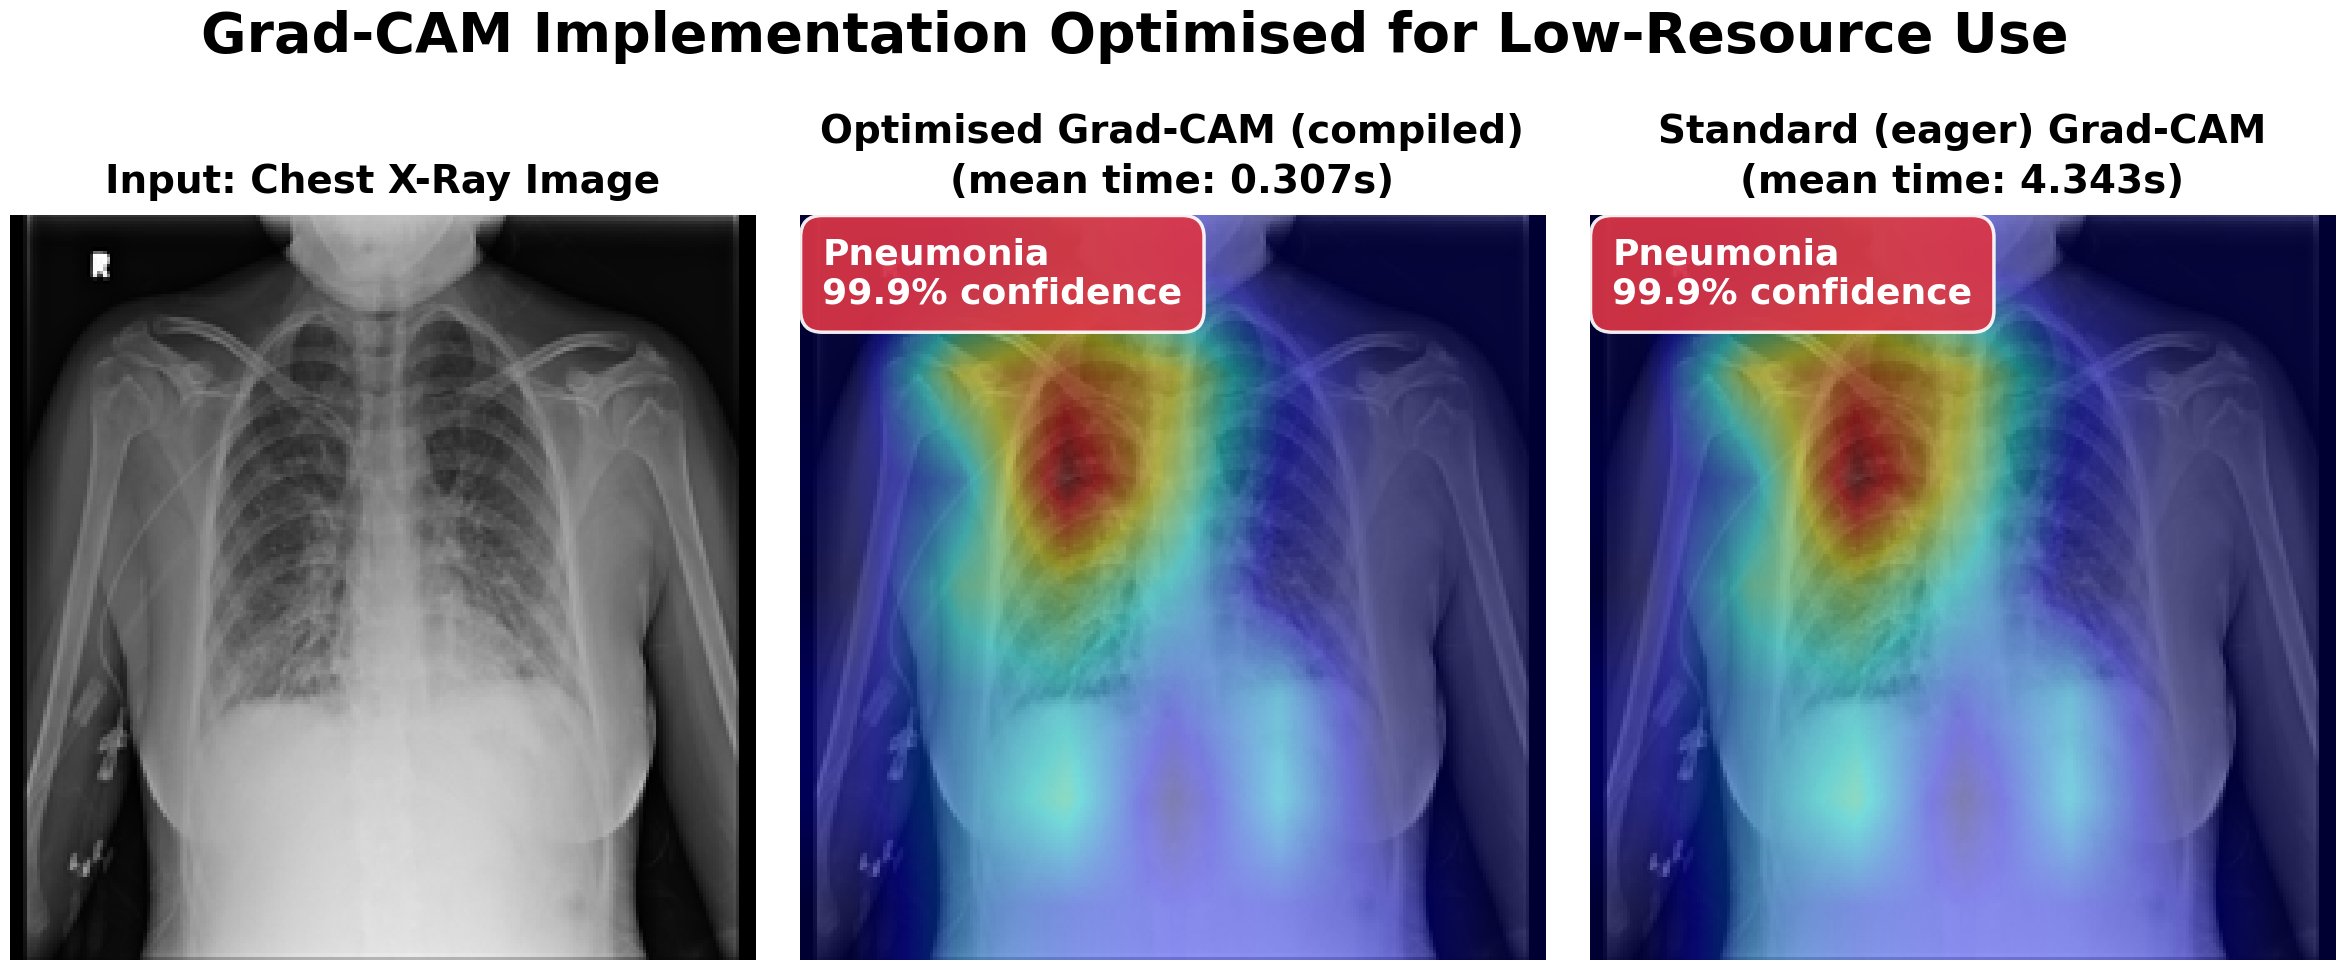

Saved: /content/gradcam_efficientnetb4_compiled.png


In [ ]:
# =============================================================================
# Grad-CAM figure: EfficientNetB4, NIH
# -----------------------------------------------------------------------------
# Three-panel Grad-CAM figure: input, optimised (compiled) Grad-CAM at native input size and
# standard (eager) Grad-CAM. Panel layout, fonts and colours are unchanged from
# the earlier version of this figure.
# Set the two mean times below to the values printed by the Grad-CAM benchmark
# cell for this model (mean seconds per image over 50 images).
# =============================================================================
import os
import gc
import psutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.applications.efficientnet import preprocess_input
import warnings
warnings.filterwarnings('ignore')

PI_CORES   = 4
PI_CPU_GHZ = 1.5
os.environ['TF_NUM_INTRAOP_THREADS'] = str(PI_CORES)
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
try:
    original_ghz = psutil.cpu_freq().current / 1000
    clock_factor = original_ghz / PI_CPU_GHZ
except Exception:
    clock_factor = 1.5

MEAN_TIME_EAGER_S    = 4.343    # standard (eager) Grad-CAM, from the benchmark cell
MEAN_TIME_COMPILED_S = 0.307    # compiled Grad-CAM, native size, from the benchmark cell
assert MEAN_TIME_EAGER_S and MEAN_TIME_COMPILED_S, 'Set the two mean times from the benchmark output.'

FS_SUPTITLE = 40
FS_PANEL    = 28
FS_BADGE    = 26

class OptimisedClinicalGradCAM:
    def __init__(self, h5_path, target_size=(224,224), clock_factor=1.0):
        self.clock_factor    = clock_factor
        self.h5_model        = load_model(h5_path)
        self.target_size     = target_size
        self.last_conv_layer = self._find_last_conv_layer()
        self.grad_model = Model(
            inputs=self.h5_model.inputs,
            outputs=[self.h5_model.get_layer(self.last_conv_layer).output,
                     self.h5_model.output])
        out_shape = self.h5_model.output_shape
        self.model_type = "softmax" if len(out_shape)==2 and out_shape[1]==2 else "sigmoid"
        self._compile_gradcam_function()

    def _find_last_conv_layer(self):
        for layer in reversed(self.h5_model.layers):
            if 'conv' in layer.name.lower() and len(layer.output.shape)==4:
                return layer.name
        raise ValueError("No conv layer found")

    def _compile_gradcam_function(self):
        @tf.function
        def _gradcam_compiled(input_tensor):
            with tf.GradientTape() as tape:
                tape.watch(input_tensor)
                conv_output, preds = self.grad_model(input_tensor)
                preds_t = tf.cast(preds, tf.float32)
                score = preds_t[:,1] if self.model_type=="softmax" else preds_t[:,0]
            grads   = tape.gradient(score, conv_output)
            pooled  = tf.reduce_mean(grads, axis=(0,1,2))
            heatmap = tf.tensordot(conv_output[0], pooled, axes=[[2],[0]])
            heatmap = tf.nn.relu(heatmap)
            heatmap = tf.image.resize(heatmap[..., tf.newaxis], self.target_size)[...,0]
            return heatmap, preds_t
        self._gradcam_compiled = _gradcam_compiled
        _ = self._gradcam_compiled(
            tf.zeros((1,*self.target_size,3), dtype=tf.float32))

    def prepare_image(self, img_path):
        img = Image.open(img_path).convert('RGB').resize(self.target_size)
        arr = np.array(img, dtype=np.float32)
        return (np.expand_dims(preprocess_input(arr.copy()), 0).astype(np.float32),
                np.array(img, dtype=np.uint8))

    def generate_compiled_gradcam(self, img_keras):
        heat_tf, preds = self._gradcam_compiled(tf.convert_to_tensor(img_keras))
        heat = heat_tf.numpy()
        heat = (heat-heat.min())/(heat.max()-heat.min()) if heat.max()>0 else np.zeros_like(heat)
        return heat, preds[0]

    def generate_full_gradcam(self, img_keras):
        inp = tf.convert_to_tensor(img_keras, dtype=tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(inp)
            conv_output, preds = self.grad_model(inp)
            preds_t = tf.cast(preds, tf.float32)
            score   = preds_t[:,1] if self.model_type=="softmax" else preds_t[:,0]
        grads   = tape.gradient(score, conv_output)
        pooled  = tf.reduce_mean(grads, axis=(0,1,2))
        heatmap = tf.tensordot(conv_output[0], pooled, axes=[[2],[0]])
        heatmap = tf.nn.relu(heatmap)
        heatmap = tf.image.resize(heatmap[..., tf.newaxis], self.target_size)[...,0]
        heat    = heatmap.numpy()
        heat    = (heat-heat.min())/(heat.max()-heat.min()) if heat.max()>0 else np.zeros_like(heat)
        return heat, preds_t[0]

    def create_overlay(self, original_img, heatmap, alpha=0.4):
        gray     = cv2.cvtColor(original_img, cv2.COLOR_RGB2GRAY)
        gray_rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
        heat_col = cv2.applyColorMap((heatmap*255).astype('uint8'), cv2.COLORMAP_JET)
        heat_col = cv2.cvtColor(heat_col, cv2.COLOR_BGR2RGB)
        return cv2.addWeighted(heat_col, alpha, gray_rgb, 1-alpha, 0)


def visualise_gradcam_3panel(h5_path, rep_img_path):
    gc.collect()
    gradcam = OptimisedClinicalGradCAM(h5_path, clock_factor=clock_factor)

    img_keras, img_display = gradcam.prepare_image(rep_img_path)
    heat_full, preds_full  = gradcam.generate_full_gradcam(img_keras)
    heat_opt,  _           = gradcam.generate_compiled_gradcam(img_keras)

    overlay_full = gradcam.create_overlay(img_display, heat_full)
    overlay_opt  = gradcam.create_overlay(img_display, heat_opt)

    if gradcam.model_type == "softmax":
        probs       = tf.nn.softmax(np.expand_dims(preds_full.numpy(), 0)).numpy()[0]
        pneumonia_p = float(probs[1])
        normal_p    = float(probs[0])
    else:
        pneumonia_p = float(np.asarray(preds_full).ravel()[0])
        normal_p    = 1.0 - pneumonia_p
    diagnosis  = "Pneumonia" if pneumonia_p > 0.5 else "Normal"
    confidence = (pneumonia_p if diagnosis=="Pneumonia" else normal_p) * 100.0
    diag_color = '#dc3545' if diagnosis=="Pneumonia" else '#28a745'

    # badge reused on both overlay panels
    badge = (diagnosis, confidence, diag_color)

    fig, axes = plt.subplots(1, 3,
                             figsize=(30, 11),
                             gridspec_kw={'wspace': 0.06})
    fig.patch.set_facecolor('white')

    panel_data = [
        (img_display,
         "Input: Chest X-Ray Image",
         None),
        (overlay_opt,
         f"Optimised Grad-CAM (compiled)\n(mean time: {MEAN_TIME_COMPILED_S:.3f}s)",
         badge),
        (overlay_full,
         f"Standard (eager) Grad-CAM\n(mean time: {MEAN_TIME_EAGER_S:.3f}s)",
         badge),
    ]

    for ax, (img, title, bdg) in zip(axes, panel_data):
        ax.imshow(img, aspect='equal')
        ax.set_title(title,
                     fontsize=FS_PANEL, fontweight='bold',
                     fontfamily='DejaVu Sans', pad=16,
                     linespacing=1.4)
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('white')
            spine.set_linewidth(2)
        if bdg:
            diag_txt, conf_val, col = bdg
            ax.text(0.03, 0.97,
                    f'{diag_txt}\n{conf_val:.1f}% confidence',
                    transform=ax.transAxes,
                    fontsize=FS_BADGE, fontweight='bold',
                    fontfamily='DejaVu Sans',
                    verticalalignment='top', color='white',
                    bbox=dict(boxstyle='round,pad=0.6',
                              facecolor=col,
                              alpha=0.92,
                              edgecolor='white',
                              linewidth=2.5))

    fig.suptitle("Grad-CAM Implementation Optimised for Low-Resource Use",
                 fontsize=FS_SUPTITLE, fontweight='bold',
                 fontfamily='DejaVu Sans', y=1.02)

    save_path = '/content/gradcam_efficientnetb4_compiled.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight',
                facecolor='white', edgecolor='none')
    plt.show()
    print(f"Saved: {save_path}")


H5_MODEL_PATH = '/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5'
REP_IMG_PATH  = '/content/drive/MyDrive/NIH_processed/test/pneumonia/00030152_000.png'
visualise_gradcam_3panel(H5_MODEL_PATH, REP_IMG_PATH)


## **7. Grad-CAM figure: Xception, Mendeley**

Set `MEAN_TIME_EAGER_S` and `MEAN_TIME_COMPILED_S` at the top of the cell to the Xception (Mendeley) means printed in section 5.

**Returns:** `/content/gradcam_xception_compiled.png`.

Representative image: /content/drive/MyDrive/chest_xray/test/PNEUMONIA/BACTERIA-1514320-0001.jpeg


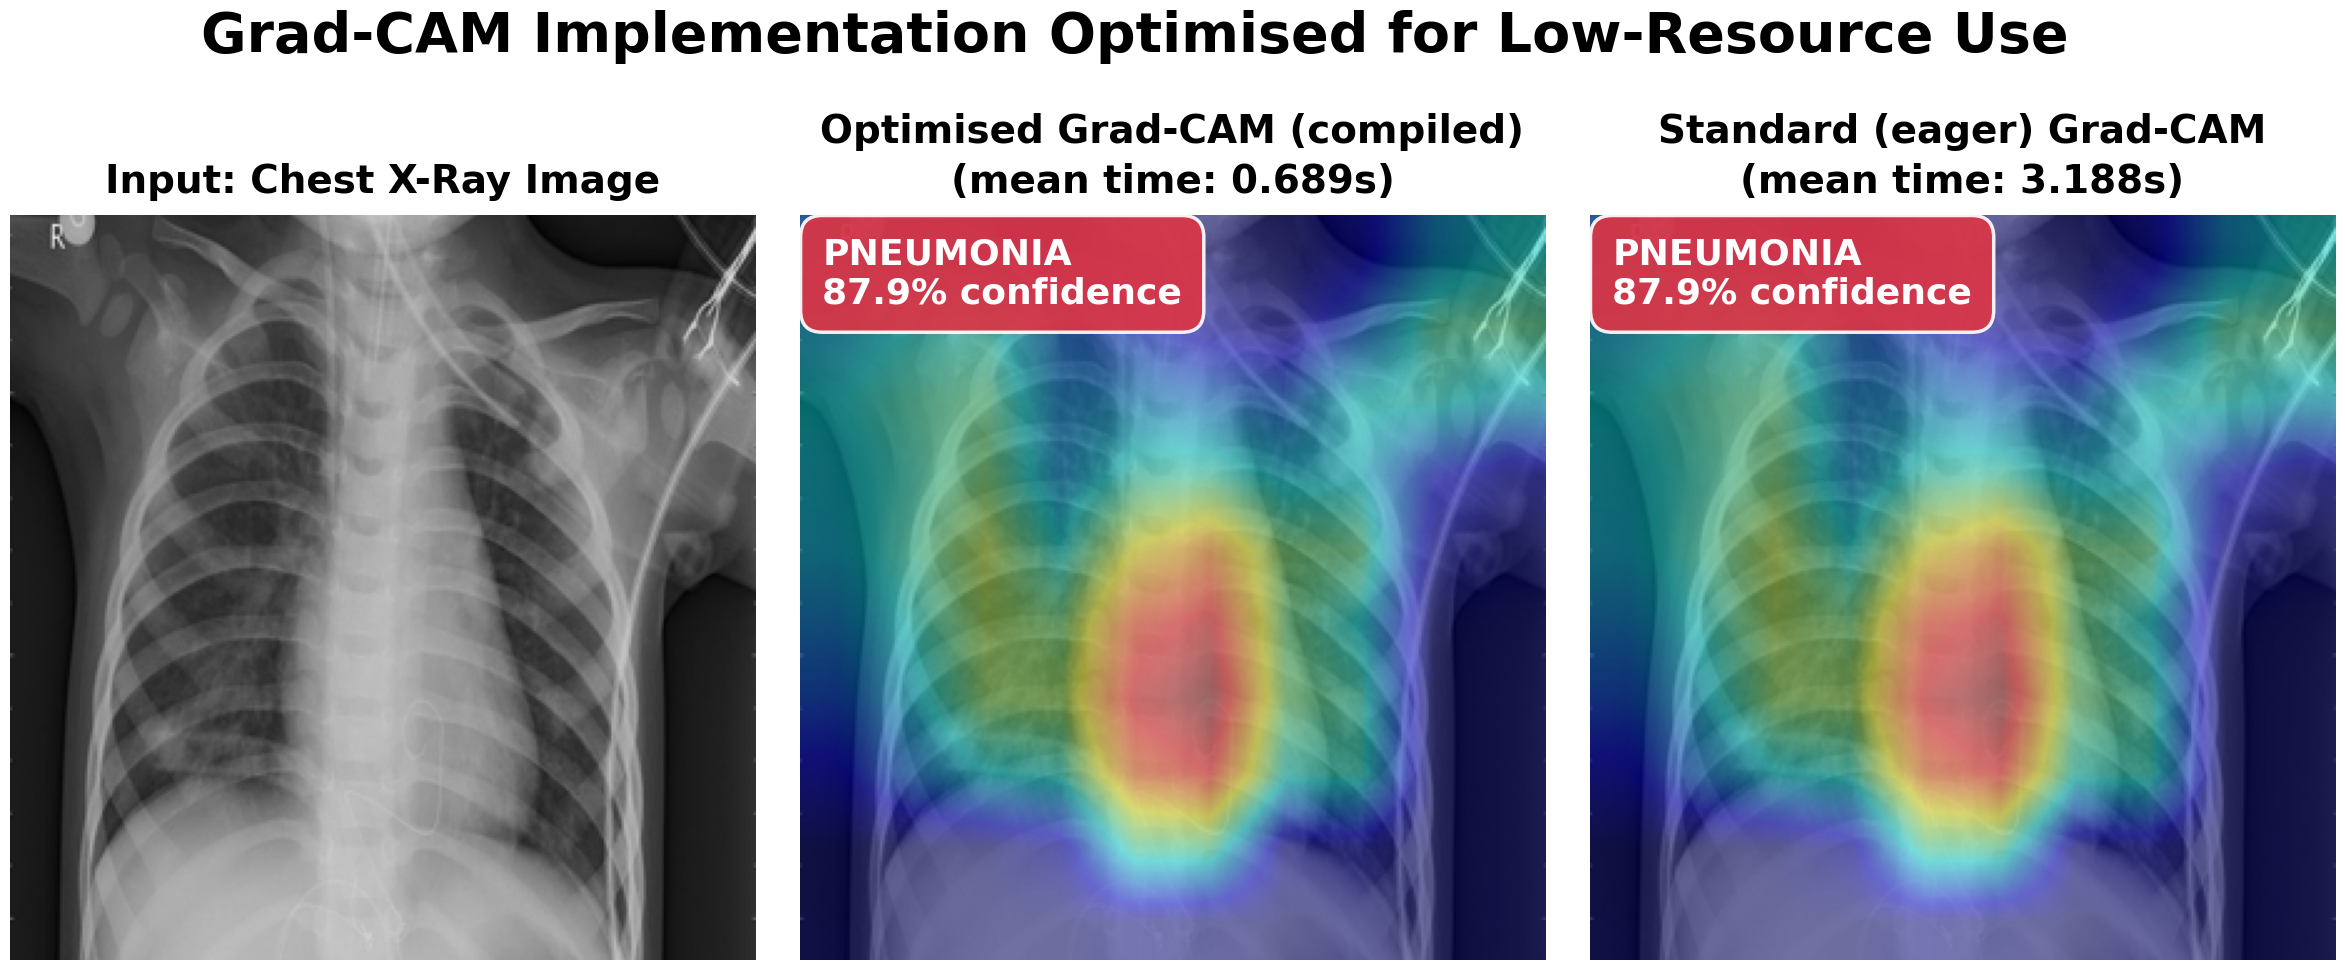

Saved: /content/gradcam_xception_compiled.png


In [ ]:
# =============================================================================
# Grad-CAM figure: Xception, Mendeley
# -----------------------------------------------------------------------------
# Three-panel Grad-CAM figure: input, optimised (compiled) Grad-CAM at native input size and
# standard (eager) Grad-CAM. Panel layout, fonts and colours are unchanged from
# the earlier version of this figure.
# Set the two mean times below to the values printed by the Grad-CAM benchmark
# cell for this model (mean seconds per image over 50 images).
# =============================================================================
import os
import glob
import gc
import random
import psutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import warnings
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
warnings.filterwarnings('ignore')

BASE_PATH  = "/content/drive/MyDrive/chest_xray"
TEST_PATH  = os.path.join(BASE_PATH, "test")
MODEL_PATH = '/content/drive/MyDrive/chest_xray/base_model_3.keras'
LABELS     = ['NORMAL', 'PNEUMONIA']
TARGET_SIZE  = (299, 299)
PI_CORES     = 4
PI_CPU_GHZ   = 1.5
SEED         = 42

MEAN_TIME_EAGER_S    = 3.188    # standard (eager) Grad-CAM, from the benchmark cell
MEAN_TIME_COMPILED_S = 0.689    # compiled Grad-CAM, native size, from the benchmark cell
assert MEAN_TIME_EAGER_S and MEAN_TIME_COMPILED_S, 'Set the two mean times from the benchmark output.'

FS_SUPTITLE = 40
FS_PANEL    = 28
FS_BADGE    = 26

os.environ['TF_NUM_INTRAOP_THREADS'] = str(PI_CORES)
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
try:
    original_ghz = psutil.cpu_freq().current / 1000.0
    clock_factor  = original_ghz / PI_CPU_GHZ
except Exception:
    clock_factor = 1.47

def ensure_probs(preds):
    arr = np.array(preds).ravel()
    if arr.size >= 2:
        if np.isclose(arr.sum(), 1.0, atol=1e-3):
            return arr.astype(np.float32)
        e = np.exp(arr - np.max(arr))
        return (e / e.sum()).astype(np.float32)
    val = float(arr[0])
    return val if 0.0 <= val <= 1.0 else 1.0/(1.0+np.exp(-val))


class XceptionGradCAM:
    def __init__(self, model_path, target_size=TARGET_SIZE, clock_factor=clock_factor):
        self.model        = load_model(model_path)
        self.target_size  = target_size
        self.clock_factor = clock_factor
        self.last_conv    = self._find_last_conv_layer()
        self.grad_model   = Model(
            inputs=self.model.inputs,
            outputs=[self.model.get_layer(self.last_conv).output,
                     self.model.output])
        out_shape       = self.model.output_shape
        self.model_type = "softmax" if len(out_shape)==2 and out_shape[1]==2 else "sigmoid"
        self._compile_optimised_gradcam()

    def _find_last_conv_layer(self):
        for layer in reversed(self.model.layers):
            if 'conv' in layer.name.lower() and len(layer.output.shape)==4:
                return layer.name
        raise ValueError("No conv layer found")

    def _compile_optimised_gradcam(self):
        @tf.function
        def _gradcam_fn(input_tensor):
            with tf.GradientTape() as tape:
                tape.watch(input_tensor)
                conv_out, preds = self.grad_model(input_tensor)
                preds_t = tf.reshape(tf.cast(preds, tf.float32), [1,-1])
                score   = preds_t[:,1] if self.model_type=="softmax" else preds_t[:,0]
            grads  = tape.gradient(score, conv_out)
            pooled = tf.reduce_mean(grads, axis=(0,1,2))
            heat   = tf.tensordot(conv_out[0], pooled, axes=[[2],[0]])
            heat   = tf.nn.relu(heat)
            heat   = tf.image.resize(heat[..., tf.newaxis], self.target_size)[...,0]
            return heat, preds_t
        self._gradcam_fn = _gradcam_fn
        _ = self._gradcam_fn(tf.zeros((1,*self.target_size,3), dtype=tf.float32))

    def prepare_image(self, path):
        img = Image.open(path).convert('RGB').resize(self.target_size)
        arr = np.array(img, dtype=np.float32)
        arr_pre = tf.keras.applications.xception.preprocess_input(
            np.expand_dims(arr, 0))
        return arr_pre.astype(np.float32), np.array(img, dtype=np.uint8)

    def generate_compiled(self, img_keras):
        heat_tf, preds = self._gradcam_fn(tf.convert_to_tensor(img_keras))
        heat = heat_tf.numpy()
        heat = (heat-heat.min())/(heat.max()-heat.min()) if heat.max()>0 else np.zeros_like(heat)
        return heat, preds[0]

    def generate_full(self, img_keras):
        inp = tf.convert_to_tensor(img_keras, dtype=tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(inp)
            conv_out, preds = self.grad_model(inp)
            preds_t = tf.reshape(tf.cast(preds, tf.float32), [1,-1])
            score   = preds_t[:,1] if self.model_type=="softmax" else preds_t[:,0]
        grads  = tape.gradient(score, conv_out)
        pooled = tf.reduce_mean(grads, axis=(0,1,2))
        heat   = tf.tensordot(conv_out[0], pooled, axes=[[2],[0]])
        heat   = tf.nn.relu(heat)
        heat   = tf.image.resize(heat[..., tf.newaxis], self.target_size)[...,0]
        heat   = heat.numpy()
        heat   = (heat-heat.min())/(heat.max()-heat.min()) if heat.max()>0 else np.zeros_like(heat)
        return heat, preds_t[0]

    def overlay(self, orig_img, heatmap, alpha=0.4):
        gray     = cv2.cvtColor(orig_img, cv2.COLOR_RGB2GRAY)
        gray_rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
        heat_col = cv2.applyColorMap((heatmap*255).astype('uint8'), cv2.COLORMAP_JET)
        heat_col = cv2.cvtColor(heat_col, cv2.COLOR_BGR2RGB)
        return cv2.addWeighted(heat_col, alpha, gray_rgb, 1-alpha, 0)


def visualise_gradcam_3panel(model_path, test_dir, rep_index=11):
    gc.collect()
    gradcam = XceptionGradCAM(model_path)

    pneumonia_folder = os.path.join(test_dir, 'PNEUMONIA')
    pneumonia_files  = sorted(
        glob.glob(os.path.join(pneumonia_folder, '*.jpeg')) +
        glob.glob(os.path.join(pneumonia_folder, '*.jpg'))  +
        glob.glob(os.path.join(pneumonia_folder, '*.png')))
    if not pneumonia_files:
        raise RuntimeError("No PNEUMONIA images found in " + pneumonia_folder)

    rep_path = pneumonia_files[rep_index % len(pneumonia_files)]
    print(f"Representative image: {rep_path}")

    img_keras, img_display = gradcam.prepare_image(rep_path)
    heat_full, preds_full  = gradcam.generate_full(img_keras)
    heat_opt,  _           = gradcam.generate_compiled(img_keras)

    overlay_full = gradcam.overlay(img_display, heat_full)
    overlay_opt  = gradcam.overlay(img_display, heat_opt)

    probs = ensure_probs(preds_full)
    if isinstance(probs, np.ndarray) and probs.size >= 2:
        normal_p, pneumonia_p = float(probs[0]), float(probs[1])
    else:
        pneumonia_p = float(probs); normal_p = 1.0 - pneumonia_p
    diagnosis  = "PNEUMONIA" if pneumonia_p > 0.5 else "NORMAL"
    confidence = (pneumonia_p if diagnosis=="PNEUMONIA" else normal_p) * 100.0
    diag_color = '#dc3545' if diagnosis=="PNEUMONIA" else '#28a745'

    # badge reused on both overlay panels
    badge = (diagnosis, confidence, diag_color)

    fig, axes = plt.subplots(1, 3,
                             figsize=(30, 11),
                             gridspec_kw={'wspace': 0.06})
    fig.patch.set_facecolor('white')

    panel_data = [
        (img_display,
         "Input: Chest X-Ray Image",
         None),
        (overlay_opt,
         f"Optimised Grad-CAM (compiled)\n(mean time: {MEAN_TIME_COMPILED_S:.3f}s)",
         badge),
        (overlay_full,
         f"Standard (eager) Grad-CAM\n(mean time: {MEAN_TIME_EAGER_S:.3f}s)",
         badge),
    ]

    for ax, (img, title, bdg) in zip(axes, panel_data):
        ax.imshow(img, aspect='equal')
        ax.set_title(title,
                     fontsize=FS_PANEL, fontweight='bold',
                     fontfamily='DejaVu Sans', pad=16,
                     linespacing=1.4)
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('white')
            spine.set_linewidth(2)
        if bdg:
            diag_txt, conf_val, col = bdg
            ax.text(0.03, 0.97,
                    f'{diag_txt}\n{conf_val:.1f}% confidence',
                    transform=ax.transAxes,
                    fontsize=FS_BADGE, fontweight='bold',
                    fontfamily='DejaVu Sans',
                    verticalalignment='top', color='white',
                    bbox=dict(boxstyle='round,pad=0.6',
                              facecolor=col,
                              alpha=0.92,
                              edgecolor='white',
                              linewidth=2.5))

    fig.suptitle("Grad-CAM Implementation Optimised for Low-Resource Use",
                 fontsize=FS_SUPTITLE, fontweight='bold',
                 fontfamily='DejaVu Sans', y=1.02)

    save_path = '/content/gradcam_xception_compiled.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight',
                facecolor='white', edgecolor='none')
    plt.show()
    print(f"Saved: {save_path}")


visualise_gradcam_3panel(MODEL_PATH, TEST_PATH, rep_index=11)


#### **GradCAM Agreement Check**

In [ ]:
# =============================================================================
# Grad-CAM agreement check: Xception (Mendeley), eager against compiled
# -----------------------------------------------------------------------------
# Lists, for the same 50 images as the benchmark cell, the maps on which the
# eager and compiled implementations disagree or on which a map is empty
# (all zero after the ReLU).
# =============================================================================
import glob
import os
import random

import numpy as np
import tensorflow as tf
from PIL import Image

MODEL_PATH = '/content/drive/MyDrive/chest_xray/base_model_3.keras'
TEST_DIR = '/content/drive/MyDrive/chest_xray/test'
CLASSES = ['NORMAL', 'PNEUMONIA']
SIZE = (299, 299)
SEED, N_PER_CLASS = 42, 25

rng = random.Random(SEED)
paths = []
for cls in CLASSES:
    files = sorted(glob.glob(os.path.join(TEST_DIR, cls, '*.jpeg')) + glob.glob(os.path.join(TEST_DIR, cls, '*.jpg'))
                   + glob.glob(os.path.join(TEST_DIR, cls, '*.png')))
    rng.shuffle(files)
    paths += [(p, cls) for p in files[:N_PER_CLASS]]

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
last = [l.name for l in model.layers if 'conv' in l.name.lower() and len(l.output.shape) == 4][-1]
grad_model = tf.keras.Model(model.inputs, [model.get_layer(last).output, model.output])


def cam(x):
    with tf.GradientTape() as tape:
        tape.watch(x)
        conv, preds = grad_model(x)
        score = tf.reshape(tf.cast(preds, tf.float32), [1, -1])[:, 1]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.nn.relu(tf.tensordot(conv[0], weights, axes=[[2], [0]]))
    return tf.image.resize(heat[..., tf.newaxis], SIZE)[..., 0]


cam_compiled = tf.function(cam)


def corr(a, b):
    a, b = a.ravel(), b.ravel()
    return float(np.corrcoef(a, b)[0, 1]) if a.std() > 1e-8 and b.std() > 1e-8 else float('nan')


print(f'{"#":>3} {"class":<10}{"max eager":>12}{"max compiled":>14}{"max |diff|":>13}{"corr (raw)":>12}')
n_empty = n_diff = 0
for i, (p, cls) in enumerate(paths):
    arr = np.array(Image.open(p).convert('RGB').resize(SIZE), dtype=np.float32)
    x = tf.convert_to_tensor(tf.keras.applications.xception.preprocess_input(arr[None]))
    h_e, h_c = cam(x).numpy(), cam_compiled(x).numpy()
    empty = h_e.max() <= 0 or h_c.max() <= 0
    differ = np.abs(h_e - h_c).max() > 1e-4 * max(h_e.max(), h_c.max(), 1e-12)
    n_empty += int(empty); n_diff += int(differ)
    if empty or differ:
        print(f'{i:>3} {cls:<10}{h_e.max():>12.3e}{h_c.max():>14.3e}{np.abs(h_e - h_c).max():>13.3e}{corr(h_e, h_c):>12.3f}')
print(f'\nImages: {len(paths)}; with an empty map: {n_empty}; with eager and compiled maps differing: {n_diff}')

  # class        max eager  max compiled   max |diff|  corr (raw)
 13 NORMAL       0.000e+00     0.000e+00    0.000e+00         nan
 19 NORMAL       0.000e+00     0.000e+00    0.000e+00         nan

Images: 50; with an empty map: 2; with eager and compiled maps differing: 0


#### **7.b GradCAM Combined**

Saved: /content/optimised_gradcam_comparison_Discover-AI.png


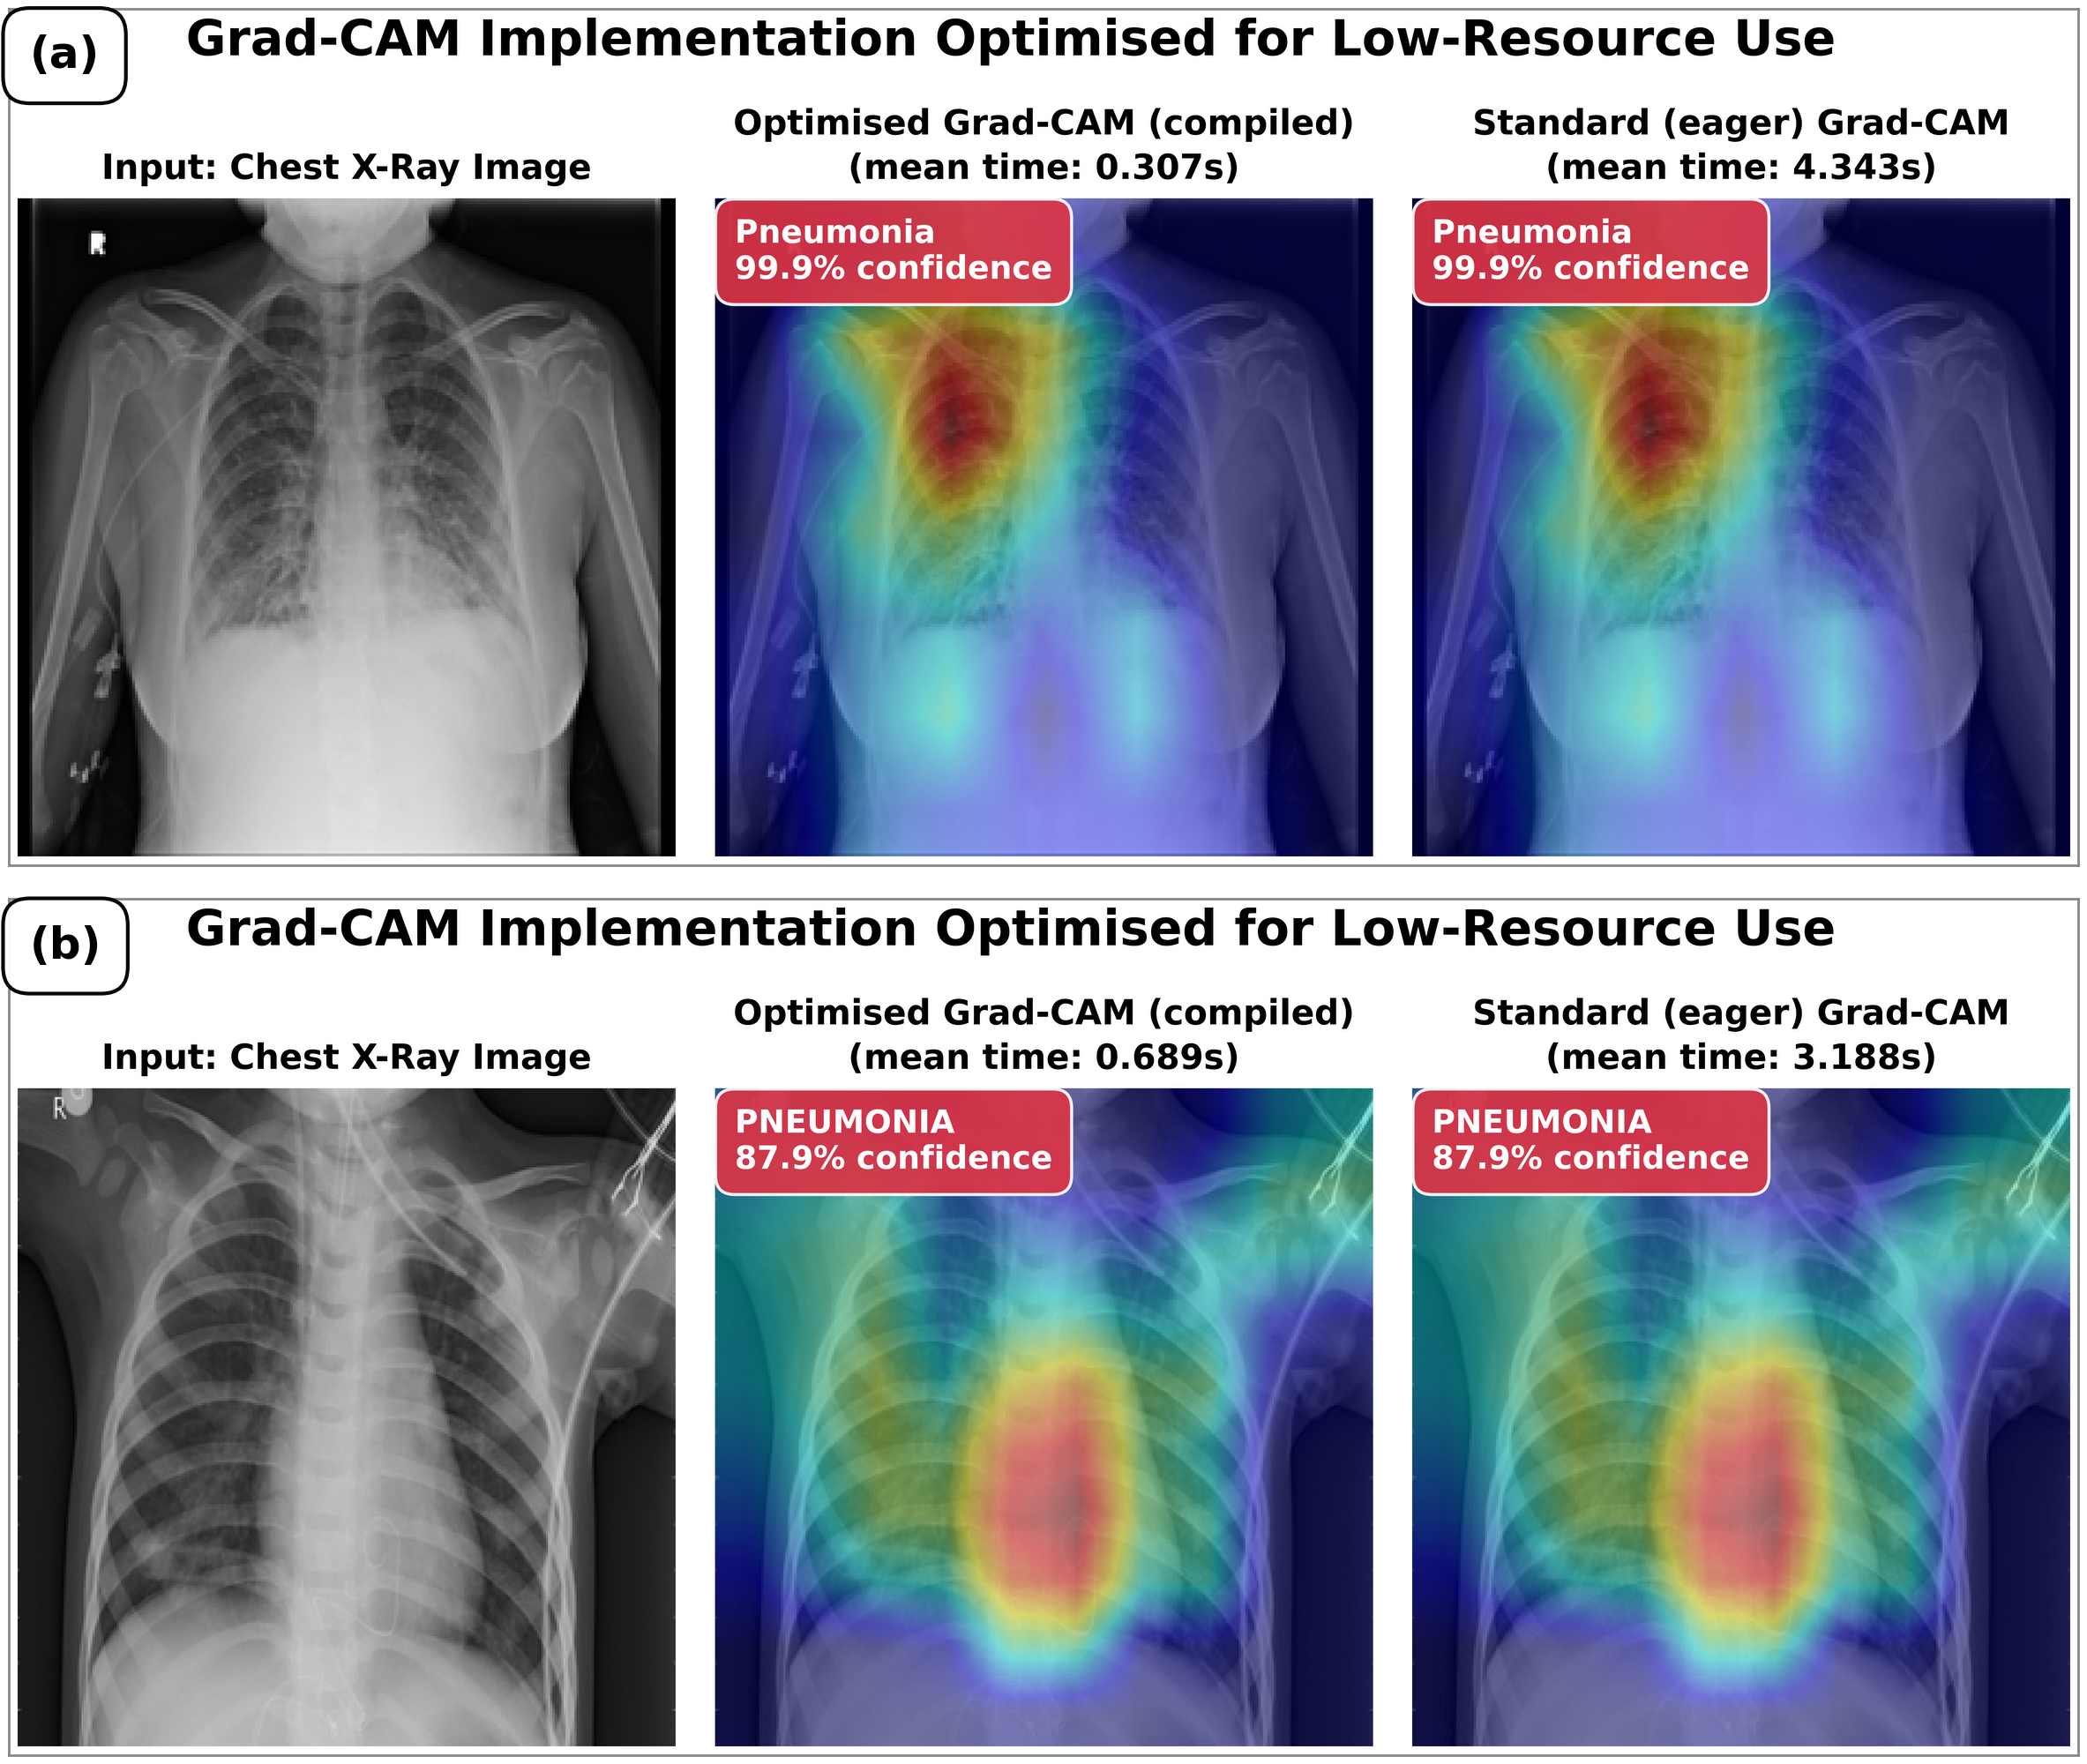

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec

img_a = mpimg.imread('/content/gradcam_efficientnetb4_compiled.png')
img_b = mpimg.imread('/content/gradcam_xception_compiled.png')

fig = plt.figure(figsize=(28, 20), facecolor='white')

gs = gridspec.GridSpec(2, 1, figure=fig,
                       left=0.005, right=0.995,
                       top=0.995, bottom=0.005,
                       hspace=0.04)

labels = ['(a)', '(b)']
images = [img_a, img_b]

for idx, (img, label) in enumerate(zip(images, labels)):
    ax = fig.add_subplot(gs[idx])
    ax.imshow(img, interpolation='lanczos')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor('#888888')
        spine.set_linewidth(2.0)
        spine.set_visible(True)
    ax.text(0.01, 0.97, label,
            transform=ax.transAxes,
            fontsize=36, fontweight='bold',
            fontfamily='DejaVu Sans',
            va='top', ha='left',
            bbox=dict(boxstyle='round,pad=0.6',
                      facecolor='white',
                      edgecolor='black',
                      linewidth=3.0,
                      alpha=0.97))

plt.savefig('/content/optimised_gradcam_comparison_Discover-AI.png',
            dpi=450, facecolor='white', edgecolor='none',
            bbox_inches='tight')
print("Saved: /content/optimised_gradcam_comparison_Discover-AI.png")
plt.show()

## **8. Model optimisation figure**

**Returns:** `model_optimisation_comparison_DiscoverAI.png` (600 dpi) and a vector PDF.

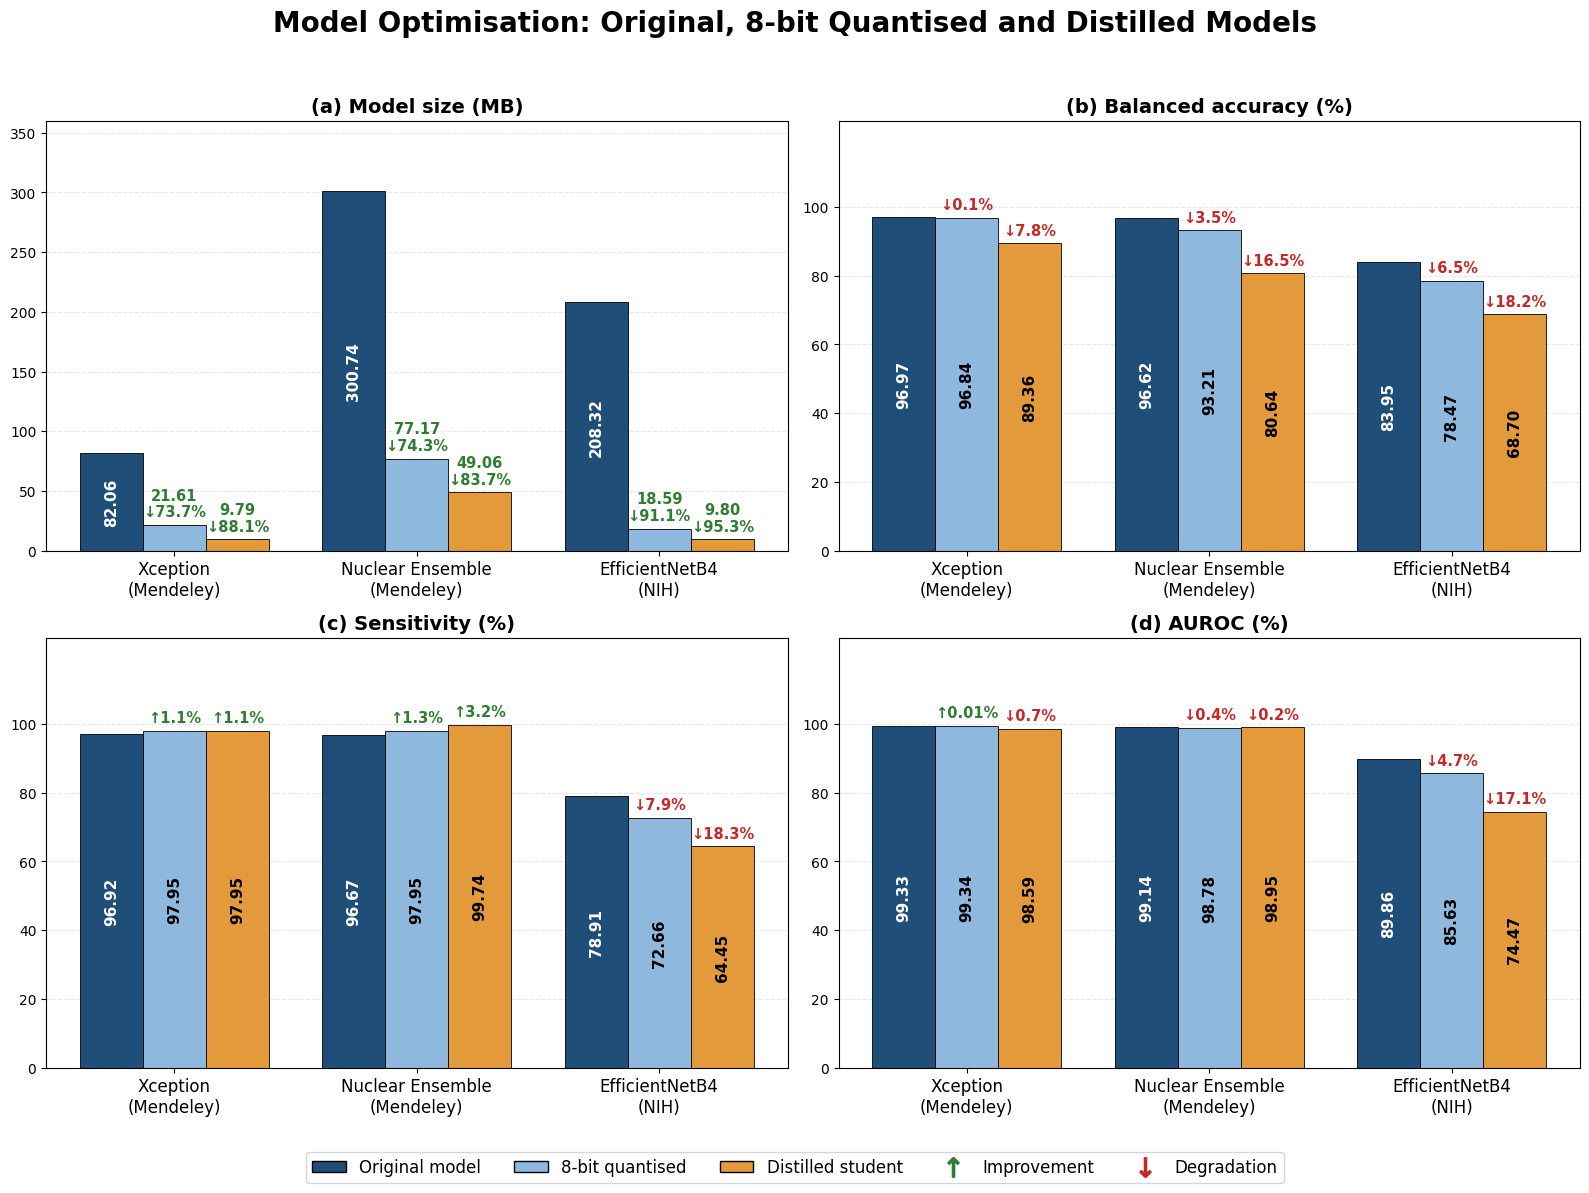

In [ ]:
# =============================================================================
# Figure 3: model size and performance of the original, 8-bit quantised and
# distilled versions of the three models
# -----------------------------------------------------------------------------
# Values are those of Table 6 (test sets, threshold 0.5). Panels: (a) model
# size, (b) balanced accuracy, (c) sensitivity, (d) AUROC. Percentages above
# the quantised and distilled bars are changes relative to the original model;
# for size a decrease counts as an improvement.
# Output: PNG at 600 dpi and a vector PDF.
# Requires only numpy and matplotlib.
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Order of versions: original, 8-bit quantised, distilled student
models = ['Xception\n(Mendeley)', 'Nuclear Ensemble\n(Mendeley)', 'EfficientNetB4\n(NIH)']
metrics = {
    'Model size (MB)':        [[82.06, 21.61, 9.79],   [300.74, 77.17, 49.06], [208.32, 18.59, 9.80]],
    'Balanced accuracy (%)':  [[96.97, 96.84, 89.36],  [96.62, 93.21, 80.64],  [83.95, 78.47, 68.70]],
    'Sensitivity (%)':        [[96.92, 97.95, 97.95],  [96.67, 97.95, 99.74],  [78.91, 72.66, 64.45]],
    'AUROC (%)':              [[99.33, 99.34, 98.59],  [99.14, 98.78, 98.95],  [89.86, 85.63, 74.47]],
}
ylims = {'Model size (MB)': 360, 'Balanced accuracy (%)': 125,
         'Sensitivity (%)': 125, 'AUROC (%)': 125}
panel_letter = {'Model size (MB)': '(a)', 'Balanced accuracy (%)': '(b)',
                'Sensitivity (%)': '(c)', 'AUROC (%)': '(d)'}

COL = ['#1f4e79', '#8fb8de', '#e39a3b']      # original, quantised, distilled
GOOD, BAD = '#2e7d32', '#c62828'
labels_v = ['Original model', '8-bit quantised', 'Distilled student']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
x = np.arange(len(models))
w = 0.26

for ax, (name, vals) in zip(axes.ravel(), metrics.items()):
    vals = np.array(vals)                      # shape (models, versions)
    ylim = ylims[name]
    for v in range(3):
        xs = x + (v - 1) * w
        hs = vals[:, v]
        ax.bar(xs, hs, w, color=COL[v], edgecolor='black', linewidth=0.6)
        for xi, h, h0 in zip(xs, hs, vals[:, 0]):
            ch = (h - h0) / h0 * 100
            tall = h > 0.22 * ylim
            # value label
            if tall:
                ax.text(xi, h / 2, f'{h:.2f}', rotation=90, ha='center', va='center',
                        fontsize=11, fontweight='bold',
                        color='white' if v == 0 else 'black')
            top = h + ylim * 0.012
            if v > 0:
                better = (ch < 0) if name.startswith('Model size') else (ch > 0)
                col = GOOD if better else BAD
                arrow = '↑' if ch > 0 else '↓'
                txt = f'{arrow}{abs(ch):.2f}%' if abs(ch) < 0.1 else f'{arrow}{abs(ch):.1f}%'
                lab = txt if tall else f'{h:.2f}\n{txt}'
                ax.text(xi, top, lab, ha='center', va='bottom', rotation=0,
                        fontsize=10.5, fontweight='bold', color=col, linespacing=1.15)
            elif not tall:
                ax.text(xi, top, f'{h:.2f}', ha='center', va='bottom',
                        fontsize=10.5, fontweight='bold')
    ax.set_title(f'{panel_letter[name]} {name}', fontsize=14, fontweight='bold')
    ax.set_ylim(0, ylim)
    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=12)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    if name != 'Model size (MB)':
        ax.set_yticks(range(0, 101, 20))

handles = [Patch(facecolor=COL[i], edgecolor='black', label=labels_v[i]) for i in range(3)]
handles += [Line2D([0], [0], marker=r'$\uparrow$', color='none', markerfacecolor=GOOD,
                   markeredgecolor=GOOD, markersize=14, linestyle='None', label='Improvement'),
            Line2D([0], [0], marker=r'$\downarrow$', color='none', markerfacecolor=BAD,
                   markeredgecolor=BAD, markersize=14, linestyle='None', label='Degradation')]
fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=12, frameon=True,
           bbox_to_anchor=(0.5, 0.0))
fig.suptitle('Model Optimisation: Original, 8-bit Quantised and Distilled Models',
             fontsize=20, fontweight='bold', y=0.985)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.savefig('model_optimisation_comparison_DiscoverAI.png', dpi=600, bbox_inches='tight')
plt.savefig('model_optimisation_comparison_DiscoverAI.pdf', bbox_inches='tight')
plt.show()


#### **Grad-CAM target layer: layer names, selection rule and effect on the map**

In [ ]:
# =============================================================================
# Grad-CAM target layer: layer names, selection rule and effect on the map
# -----------------------------------------------------------------------------
# For each Grad-CAM model, prints the last ten layer names, the layer chosen by
# the rule used in the Grad-CAM scripts (last layer whose name contains 'conv'
# and whose output is a four-dimensional feature map), its output shape, and
# the last four-dimensional layer overall. Where the two differ, the maps from
# both are compared on 10 test images (5 per class, seed 42).
# =============================================================================
import glob
import os
import random

import numpy as np
import tensorflow as tf
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

SEED, N_PER_CLASS = 42, 5
CONFIGS = {
    'Xception (Mendeley)': dict(
        model_path='/content/drive/MyDrive/chest_xray/base_model_3.keras',
        test_dir='/content/drive/MyDrive/chest_xray/test',
        classes=['NORMAL', 'PNEUMONIA'], size=(299, 299),
        preprocess=tf.keras.applications.xception.preprocess_input),
    'EfficientNetB4 (NIH)': dict(
        model_path='/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5',
        test_dir='/content/drive/MyDrive/NIH_processed/test',
        classes=['normal', 'pneumonia'], size=(224, 224),
        preprocess=tf.keras.applications.efficientnet.preprocess_input),
}


def select_images(test_dir, classes):
    rng, chosen = random.Random(SEED), []
    for cls in classes:
        folder = os.path.join(test_dir, cls)
        files = sorted(glob.glob(os.path.join(folder, '*.jpeg')) + glob.glob(os.path.join(folder, '*.jpg'))
                       + glob.glob(os.path.join(folder, '*.png')))
        rng.shuffle(files)
        chosen += files[:N_PER_CLASS]
    return chosen


def last_conv_name(model):
    for layer in reversed(model.layers):
        if 'conv' in layer.name.lower() and len(layer.output.shape) == 4:
            return layer.name
    raise ValueError('No convolutional layer found')


def last_4d_name(model):
    return [l.name for l in model.layers if len(l.output.shape) == 4][-1]


def normalise(h):
    h = np.asarray(h, dtype=np.float64)
    span = h.max() - h.min()
    return (h - h.min()) / span if h.max() > 0 and span > 0 else np.zeros_like(h)


def correlation(a, b):
    a, b = a.ravel(), b.ravel()
    return 0.0 if a.std() < 1e-8 or b.std() < 1e-8 else float(np.corrcoef(a, b)[0, 1])


def iou(a, b, thr=0.5):
    a, b = a >= thr, b >= thr
    u = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / u) if u else 0.0


def make_cam(model, layer_name, target):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    softmax_head = len(model.output_shape) == 2 and model.output_shape[1] == 2

    def cam(x):
        with tf.GradientTape() as tape:
            tape.watch(x)
            conv, preds = grad_model(x)
            preds = tf.reshape(tf.cast(preds, tf.float32), [1, -1])
            score = preds[:, 1] if softmax_head else preds[:, 0]
        grads = tape.gradient(score, conv)
        weights = tf.reduce_mean(grads, axis=(0, 1, 2))
        heat = tf.nn.relu(tf.tensordot(conv[0], weights, axes=[[2], [0]]))
        return tf.image.resize(heat[..., tf.newaxis], target)[..., 0].numpy()
    return cam


for title, cfg in CONFIGS.items():
    model = tf.keras.models.load_model(cfg['model_path'], compile=False)
    chosen, last4d = last_conv_name(model), last_4d_name(model)
    print(f'\n{title}')
    print('  last ten layers :', [l.name for l in model.layers][-10:])
    print(f'  selected layer  : {chosen}   output shape {model.get_layer(chosen).output.shape}')
    print(f'  last 4-D layer  : {last4d}   output shape {model.get_layer(last4d).output.shape}')
    if chosen != last4d:
        cam_a, cam_b = make_cam(model, chosen, cfg['size']), make_cam(model, last4d, cfg['size'])
        r, u = [], []
        for p in select_images(cfg['test_dir'], cfg['classes']):
            arr = np.array(Image.open(p).convert('RGB').resize(cfg['size']), dtype=np.float32)
            x = tf.convert_to_tensor(cfg['preprocess'](arr[None]).astype(np.float32))
            a, b = normalise(cam_a(x)), normalise(cam_b(x))
            r.append(correlation(a, b)); u.append(iou(a, b))
        print(f'  maps from {chosen} against {last4d}, {len(r)} images: '
              f'correlation {np.mean(r):.3f}, IoU@0.5 {np.mean(u):.3f}')
    tf.keras.backend.clear_session()

Mounted at /content/drive

Xception (Mendeley)
  last ten layers : ['block14_sepconv1', 'block14_sepconv1_bn', 'block14_sepconv1_act', 'block14_sepconv2', 'block14_sepconv2_bn', 'block14_sepconv2_act', 'global_average_pooling2d_3', 'dense_6', 'dropout_3', 'dense_7']
  selected layer  : block14_sepconv2_act   output shape (None, 10, 10, 2048)
  last 4-D layer  : block14_sepconv2_act   output shape (None, 10, 10, 2048)

EfficientNetB4 (NIH)
  last ten layers : ['block7b_project_bn', 'block7b_drop', 'block7b_add', 'top_conv', 'top_bn', 'top_activation', 'global_average_pooling2d', 'dense', 'dropout', 'dense_1']
  selected layer  : top_conv   output shape (None, 7, 7, 1792)
  last 4-D layer  : top_activation   output shape (None, 7, 7, 1792)
  maps from top_conv against top_activation, 10 images: correlation 0.849, IoU@0.5 0.623


#### **Optimised Grad-CAM: native size against 128 x 128 input (rebuilt network, shared weights)**

In [ ]:
# =============================================================================
# Optimised Grad-CAM: eager, compiled (native size) and compiled (128 x 128)
# -----------------------------------------------------------------------------
# The saved networks accept only their native input size. For the 128 x 128
# setting the same architecture is rebuilt with a 128 x 128 input and the
# trained weights are copied across (by position, then by layer name; the state
# of normalisation layers is then recomputed). The copy is checked first at
# native size: it must reproduce the original output, and if it does not, the
# first layer at which the two networks diverge is printed. The same 50 test
# images as the earlier benchmark are then explained three ways: eager
# (standard), compiled at native size, compiled at 128 x 128. Each 128 x 128
# map is resized to native size and compared with the eager map. Agreement is
# computed on images whose eager map is not empty. Times cover the Grad-CAM
# computation only and are multiplied by (host clock / 1.5 GHz).
# =============================================================================
import glob
import os
import random
import time

import numpy as np
import psutil
import tensorflow as tf
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

PI_GHZ, SEED, N_PER_CLASS, SMALL = 1.5, 42, 25, (128, 128)
CONFIGS = {
    'Xception (Mendeley)': dict(
        model_path='/content/drive/MyDrive/chest_xray/base_model_3.keras',
        test_dir='/content/drive/MyDrive/chest_xray/test',
        classes=['NORMAL', 'PNEUMONIA'], size=(299, 299),
        preprocess=tf.keras.applications.xception.preprocess_input),
    'EfficientNetB4 (NIH)': dict(
        model_path='/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5',
        test_dir='/content/drive/MyDrive/NIH_processed/test',
        classes=['normal', 'pneumonia'], size=(224, 224),
        preprocess=tf.keras.applications.efficientnet.preprocess_input),
}

try:
    host_ghz = psutil.cpu_freq().current / 1000.0
    note = ''
except Exception:
    host_ghz, note = 2.2, ' (clock not reported; 2.2 GHz assumed)'
clock_factor = host_ghz / PI_GHZ
print(f'Host: {host_ghz * 1000:.0f} MHz, {psutil.cpu_count(logical=False)} physical / '
      f'{psutil.cpu_count(logical=True)} logical cores; clock factor {clock_factor:.2f}{note}')


def select_images(test_dir, classes):
    rng, chosen = random.Random(SEED), []
    for cls in classes:
        folder = os.path.join(test_dir, cls)
        files = sorted(glob.glob(os.path.join(folder, '*.jpeg')) + glob.glob(os.path.join(folder, '*.jpg'))
                       + glob.glob(os.path.join(folder, '*.png')))
        rng.shuffle(files)
        chosen += files[:N_PER_CLASS]
    return chosen


def last_conv_name(model):
    for layer in reversed(model.layers):
        if 'conv' in layer.name.lower() and len(layer.output.shape) == 4:
            return layer.name
    raise ValueError('No convolutional layer found')


def normalise(h):
    h = np.asarray(h, dtype=np.float64)
    span = h.max() - h.min()
    return (h - h.min()) / span if h.max() > 0 and span > 0 else np.zeros_like(h)


def correlation(a, b):
    a, b = a.ravel(), b.ravel()
    return 0.0 if a.std() < 1e-8 or b.std() < 1e-8 else float(np.corrcoef(a, b)[0, 1])


def iou(a, b, thr=0.5):
    a, b = a >= thr, b >= thr
    u = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / u) if u else 0.0


def rebuild_for_input(model, size):
    """Same architecture and trained weights, with a new fixed input size."""
    new_input = tf.keras.Input(shape=(size[0], size[1], 3))
    inputs = [new_input] if isinstance(model.input, (list, tuple)) else new_input
    clone = tf.keras.models.clone_model(model, input_tensors=inputs)
    clone.set_weights(model.get_weights())                  # copy by position
    for layer in model.layers:                              # then by layer name
        if layer.weights:
            clone.get_layer(layer.name).set_weights(layer.get_weights())
    for layer in clone.layers:                              # recompute normalisation state from copied statistics
        if hasattr(layer, 'finalize_state'):
            layer.finalize_state()
    return clone


def first_divergence(model, clone, x):
    """First layer (in model order) whose output differs between the original and the rebuilt network."""
    names = [l.name for l in model.layers
             if not isinstance(l, tf.keras.layers.InputLayer) and len(l.output.shape) >= 2]
    a = tf.keras.Model(model.inputs, [model.get_layer(n).output for n in names])
    b = tf.keras.Model(clone.inputs, [clone.get_layer(n).output for n in names])
    for n, ya, yb in zip(names, a(x, training=False), b(x, training=False)):
        d = float(np.max(np.abs(np.asarray(ya) - np.asarray(yb))))
        if d > 1e-3 * (float(np.max(np.abs(np.asarray(ya)))) + 1e-12):
            return n, type(model.get_layer(n)).__name__, d
    return None


def make_cam(model, layer_name, out_size):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    softmax_head = len(model.output_shape) == 2 and model.output_shape[1] == 2

    def cam(x):
        with tf.GradientTape() as tape:
            tape.watch(x)
            conv, preds = grad_model(x)
            preds = tf.reshape(tf.cast(preds, tf.float32), [1, -1])
            score = preds[:, 1] if softmax_head else preds[:, 0]
        grads = tape.gradient(score, conv)
        weights = tf.reduce_mean(grads, axis=(0, 1, 2))
        heat = tf.nn.relu(tf.tensordot(conv[0], weights, axes=[[2], [0]]))
        return tf.image.resize(heat[..., tf.newaxis], out_size)[..., 0]
    return cam


def probability(model, x):
    y = np.asarray(model(x, training=False)).ravel()
    return float(y[1] if y.size == 2 else y[0])


def run(title, cfg):
    model = tf.keras.models.load_model(cfg['model_path'], compile=False)
    layer, native = last_conv_name(model), cfg['size']
    check, small = rebuild_for_input(model, native), rebuild_for_input(model, SMALL)

    def load(path):
        arr = np.array(Image.open(path).convert('RGB').resize(native), dtype=np.float32)
        return tf.convert_to_tensor(cfg['preprocess'](arr[None]).astype(np.float32))

    paths = select_images(cfg['test_dir'], cfg['classes'])
    first = load(paths[0])
    copy_error = float(np.max(np.abs(np.asarray(model(first, training=False))
                                     - np.asarray(check(first, training=False)))))
    print(f'\n{title}: layer {layer}; weight-copy check at native size, max |difference| = {copy_error:.2e}')
    if copy_error >= 1e-4:
        print('  first diverging layer (name, class, max difference):', first_divergence(model, check, first))
    assert copy_error < 1e-4, 'rebuilt network does not reproduce the original'

    cam_eager = make_cam(model, layer, native)
    cam_native = tf.function(make_cam(model, layer, native))
    cam_small = tf.function(make_cam(small, layer, native))
    first_small = tf.image.resize(first, SMALL, method='bilinear')
    cam_eager(first); cam_native(first); cam_small(first_small)                # warm-up

    t = {'eager': [], 'native': [], 'small': []}
    r = {'native': [], 'small': []}
    u = {'native': [], 'small': []}
    dp, same_class, defined = [], 0, 0
    for p in paths:
        x = load(p)
        xs = tf.image.resize(x, SMALL, method='bilinear')
        t0 = time.perf_counter(); h_e = cam_eager(x)
        t['eager'].append((time.perf_counter() - t0) * clock_factor)
        t0 = time.perf_counter(); h_n = cam_native(x)
        t['native'].append((time.perf_counter() - t0) * clock_factor)
        t0 = time.perf_counter(); h_s = cam_small(xs)
        t['small'].append((time.perf_counter() - t0) * clock_factor)

        p_nat, p_small = probability(model, x), probability(small, xs)
        dp.append(abs(p_nat - p_small))
        same_class += int((p_nat >= 0.5) == (p_small >= 0.5))
        ref = normalise(h_e.numpy())
        if ref.max() > 0:
            defined += 1
            for key, h in (('native', h_n), ('small', h_s)):
                h = normalise(h.numpy())
                r[key].append(correlation(ref, h)); u[key].append(iou(ref, h))

    n = len(paths)
    print(f'  {n} images; eager map defined on {defined}')
    print(f"  eager                 {np.mean(t['eager']):7.3f} +/- {np.std(t['eager']):.3f} s")
    for key, label in (('native', 'compiled, native size'), ('small', 'compiled, 128 x 128')):
        print(f"  {label:<22}{np.mean(t[key]):7.3f} +/- {np.std(t[key]):.3f} s   "
              f"speed-up {np.mean(t['eager']) / np.mean(t[key]):5.2f}x   "
              f"correlation {np.mean(r[key]):.3f}   IoU@0.5 {np.mean(u[key]):.3f}")
    print(f'  128 x 128 network against native network: mean |change in probability| {np.mean(dp):.4f}; '
          f'same predicted class on {same_class} of {n} images')
    tf.keras.backend.clear_session()


for title, cfg in CONFIGS.items():
    run(title, cfg)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Host: 2200 MHz, 1 physical / 2 logical cores; clock factor 1.47

Xception (Mendeley): layer block14_sepconv2_act; weight-copy check at native size, max |difference| = 0.00e+00
  50 images; eager map defined on 48
  eager                   3.150 +/- 0.935 s
  compiled, native size   0.650 +/- 0.201 s   speed-up  4.85x   correlation 1.000   IoU@0.5 1.000
  compiled, 128 x 128     0.159 +/- 0.078 s   speed-up 19.77x   correlation 0.343   IoU@0.5 0.186
  128 x 128 network against native network: mean |change in probability| 0.3348; same predicted class on 28 of 50 images

EfficientNetB4 (NIH): layer top_conv; weight-copy check at native size, max |difference| = 0.00e+00
  50 images; eager map defined on 50
  eager                   3.671 +/- 0.656 s
  compiled, native size   0.311 +/- 0.075 s   speed-up 11.80x   correlation 1.000   IoU@0.5 1.000
  compiled, 128 x

#### **TensorFlow Lite timing at explicit thread counts: FP32 against quantised files**

In [ ]:
# =============================================================================
# TensorFlow Lite timing at explicit thread counts (FP32 against quantised)
# -----------------------------------------------------------------------------
# Workloads: NIH EfficientNetB4 (dynamic range), Xception (full integer),
# 14-label EfficientNetB4 (dynamic range), Nuclear Ensemble (full integer, five
# members run in sequence). Each FP32 file and its quantised counterpart are
# timed in the same session, alternating image by image, with the interpreter
# thread count set explicitly (None = interpreter default). Batch size 1, one
# warm-up call, 20 images, interpreter call only (loading and pre-processing
# excluded, for the ensemble too). Times are multiplied by (host clock / 1.5 GHz).
# Unreadable images are retried and then skipped; the first 20 readable images
# of each list are used. ONLY restricts the run to workloads whose name
# contains one of the listed strings (empty list = all four).
# =============================================================================
import glob
import os
import time

import numpy as np
import pandas as pd
import psutil
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

PI_GHZ, THREADS, N_IMAGES = 1.5, [None, 1, 2, 4], 20
ONLY = ['14-label', 'Nuclear']
CHEST = '/content/drive/MyDrive/chest_xray'
INT8_DIR, FP32_DIR = f'{CHEST}/PTQ_Quantized_Ensemble', f'{CHEST}/FP32_TFLite_Ensemble'
ML = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized'
NIH_H5 = '/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5'
NIH_TEST = '/content/drive/MyDrive/NIH_processed/test'
VAL_XLSX = '/content/drive/MyDrive/Multi_Label_Classification/val_original.xlsx'
V6_IMAGES = '/content/drive/MyDrive/NIH_ChestXray/images_extracted/images'
WORK = '/content/thread_sweep'
os.makedirs(WORK, exist_ok=True)

try:
    host_ghz = psutil.cpu_freq().current / 1000.0
    note = ''
except Exception:
    host_ghz, note = 2.2, ' (clock not reported; 2.2 GHz assumed)'
clock_factor = host_ghz / PI_GHZ
print(f'Host: {host_ghz * 1000:.0f} MHz, {psutil.cpu_count(logical=False)} physical / '
      f'{psutil.cpu_count(logical=True)} logical cores; clock factor {clock_factor:.2f}{note}')

#  NIH EfficientNetB4: FP32 and dynamic-range files
nih_fp32, nih_dyn = f'{WORK}/nih_effnetb4_fp32.tflite', f'{WORK}/nih_effnetb4_dynamic.tflite'
if not (os.path.exists(nih_fp32) and os.path.exists(nih_dyn)):
    nih_model = tf.keras.models.load_model(NIH_H5, compile=False)
    open(nih_fp32, 'wb').write(tf.lite.TFLiteConverter.from_keras_model(nih_model).convert())
    conv = tf.lite.TFLiteConverter.from_keras_model(nih_model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    open(nih_dyn, 'wb').write(conv.convert())
    del nih_model
print(f'NIH EfficientNetB4: FP32 {os.path.getsize(nih_fp32) / 1024 ** 2:.2f} MB, '
      f'dynamic range {os.path.getsize(nih_dyn) / 1024 ** 2:.2f} MB')

#  workloads
identity = lambda a: a
ens_pre = [tf.keras.applications.resnet.preprocess_input, tf.keras.applications.densenet.preprocess_input,
           tf.keras.applications.inception_v3.preprocess_input, tf.keras.applications.xception.preprocess_input,
           tf.keras.applications.mobilenet_v2.preprocess_input]


def two_class(root, classes, ext):
    lists = [sorted(glob.glob(os.path.join(root, c, ext)))[:N_IMAGES] for c in classes]
    return [p for pair in zip(*lists) for p in pair]            # interleaved, with spare candidates


nih_images = two_class(NIH_TEST, ['normal', 'pneumonia'], '*.png')
mend_images = two_class(f'{CHEST}/test', ['NORMAL', 'PNEUMONIA'], '*.jp*g')
_, half = train_test_split(pd.read_excel(VAL_XLSX), test_size=0.5, random_state=123)
v6_images = [os.path.join(V6_IMAGES, n) for n in half['Image Index'].iloc[:N_IMAGES * 3]]

WORKLOADS = [
    ('NIH EfficientNetB4 (dynamic range)', [(nih_fp32, nih_dyn, identity)], nih_images),
    ('Xception (full integer)', [(f'{FP32_DIR}/base_model_3_fp32.tflite', f'{INT8_DIR}/base_model_3_int8.tflite',
                                  ens_pre[3])], mend_images),
    ('14-label EfficientNetB4 (dynamic range)', [(f'{ML}/v6_fp32.tflite', f'{ML}/v6_quantized_hybrid_int8.tflite',
                                                  identity)], v6_images),
    ('Nuclear Ensemble (full integer)', [(f'{FP32_DIR}/base_model_{i}_fp32.tflite',
                                          f'{INT8_DIR}/base_model_{i}_int8.tflite', ens_pre[i])
                                         for i in range(5)], mend_images),
]
if ONLY:
    WORKLOADS = [w for w in WORKLOADS if any(s in w[0] for s in ONLY)]
for _, members, _ in WORKLOADS:
    for fp, q, _ in members:
        assert os.path.exists(fp) and os.path.exists(q), f'missing file: {fp} or {q}'


def read_image(path, retries=3):
    for attempt in range(retries):
        try:
            with open(path, 'rb') as f:
                f.read()
            return Image.open(path).convert('RGB')
        except OSError:
            time.sleep(2)
    return None


def prepare_inputs(members, images):
    sizes = []
    for _, q, _ in members:
        shape = tf.lite.Interpreter(model_path=q).get_input_details()[0]['shape']
        sizes.append((int(shape[2]), int(shape[1])))
    inputs, skipped = [], 0
    for p in images:
        if len(inputs) == N_IMAGES:
            break
        img = read_image(p)
        if img is None:
            skipped += 1
            continue
        inputs.append([pre(np.array(img.resize(s), dtype=np.float32)[None]).astype(np.float32)
                       for (_, _, pre), s in zip(members, sizes)])
    print(f'  {len(inputs)} images loaded, {skipped} unreadable image(s) skipped')
    return inputs


def build(paths, threads):
    runners = []
    for p in paths:
        it = (tf.lite.Interpreter(model_path=p) if threads is None
              else tf.lite.Interpreter(model_path=p, num_threads=threads))
        it.allocate_tensors()
        runners.append((it, it.get_input_details()[0]['index'], it.get_output_details()[0]['index']))
    return runners


def invoke(runners, arrays):
    for (it, i_in, i_out), a in zip(runners, arrays):
        it.set_tensor(i_in, a)
        it.invoke()
        it.get_tensor(i_out)


rows = []
for name, members, images in WORKLOADS:
    print(f'\n{name}')
    inputs = prepare_inputs(members, images)
    for threads in THREADS:
        fp32 = build([m[0] for m in members], threads)
        quant = build([m[1] for m in members], threads)
        invoke(fp32, inputs[0]); invoke(quant, inputs[0])                       # warm-up
        t_fp, t_q = [], []
        for i, arrays in enumerate(inputs):
            order = [('fp', fp32), ('q', quant)]
            if i % 2:
                order.reverse()
            for tag, runners in order:
                t0 = time.perf_counter(); invoke(runners, arrays)
                ms = (time.perf_counter() - t0) * 1000 * clock_factor
                (t_fp if tag == 'fp' else t_q).append(ms)
        rows.append(dict(workload=name, threads='default' if threads is None else threads,
                         fp32_ms=f'{np.mean(t_fp):.1f} +/- {np.std(t_fp):.1f}',
                         quantised_ms=f'{np.mean(t_q):.1f} +/- {np.std(t_q):.1f}',
                         quantised_over_fp32=round(float(np.mean(t_q) / np.mean(t_fp)), 2)))
        print(rows[-1])

print('\n', pd.DataFrame(rows).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Host: 2200 MHz, 1 physical / 2 logical cores; clock factor 1.47
NIH EfficientNetB4: FP32 68.63 MB, dynamic range 18.62 MB

14-label EfficientNetB4 (dynamic range)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


  20 images loaded, 0 unreadable image(s) skipped
{'workload': '14-label EfficientNetB4 (dynamic range)', 'threads': 'default', 'fp32_ms': '131.5 +/- 5.9', 'quantised_ms': '202.9 +/- 8.6', 'quantised_over_fp32': 1.54}
{'workload': '14-label EfficientNetB4 (dynamic range)', 'threads': 1, 'fp32_ms': '169.6 +/- 36.6', 'quantised_ms': '248.4 +/- 50.0', 'quantised_over_fp32': 1.46}
{'workload': '14-label EfficientNetB4 (dynamic range)', 'threads': 2, 'fp32_ms': '126.4 +/- 20.8', 'quantised_ms': '222.4 +/- 54.0', 'quantised_over_fp32': 1.76}
{'workload': '14-label EfficientNetB4 (dynamic range)', 'threads': 4, 'fp32_ms': '154.3 +/- 23.9', 'quantised_ms': '306.7 +/- 61.7', 'quantised_over_fp32': 1.99}

Nuclear Ensemble (full integer)
  20 images loaded, 0 unreadable image(s) skipped
{'workload': 'Nuclear Ensemble (full integer)', 'threads': 'default', 'fp32_ms': '1300.9 +/- 252.8', 'quantised_ms': '1427.7 +/- 274.3', 'quantised_over_fp32': 1.1}
{'workload': 'Nuclear Ensemble (full integer)', 

#### **TensorFlow Lite timing with and without the default XNNPack delegate**

In [ ]:
# =============================================================================
# TensorFlow Lite timing with and without the default XNNPack delegate
# -----------------------------------------------------------------------------
# Control experiment for the FP32 against quantised timing. Each pair of files
# is timed twice in the same session: with the interpreter's default kernels
# (XNNPack delegate applied where supported) and with the default delegates
# disabled (built-in kernels only). Batch size 1, one warm-up call, 20 images,
# default thread setting, interpreter call only, times multiplied by
# (host clock / 1.5 GHz), alternating FP32 and quantised image by image.
# =============================================================================
import glob
import os
import time

import numpy as np
import pandas as pd
import psutil
import tensorflow as tf
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

PI_GHZ, N_IMAGES = 1.5, 20
CHEST = '/content/drive/MyDrive/chest_xray'
WORK = '/content/thread_sweep'
V6 = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized'
NIH_TEST = '/content/drive/MyDrive/NIH_processed/test'
RESOLVERS = {'default kernels': tf.lite.experimental.OpResolverType.AUTO,
             'built-in only (no XNNPack)': tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES}

host_ghz = psutil.cpu_freq().current / 1000.0 if psutil.cpu_freq() else 2.2
clock_factor = host_ghz / PI_GHZ
print(f'TensorFlow {tf.__version__}; host {host_ghz * 1000:.0f} MHz, {psutil.cpu_count(logical=False)} physical / '
      f'{psutil.cpu_count(logical=True)} logical cores; clock factor {clock_factor:.2f}')

nih_images = sorted(glob.glob(f'{NIH_TEST}/normal/*.png'))[:N_IMAGES // 2] + \
             sorted(glob.glob(f'{NIH_TEST}/pneumonia/*.png'))[:N_IMAGES // 2]
mend_images = sorted(glob.glob(f'{CHEST}/test/NORMAL/*.jp*g'))[:N_IMAGES // 2] + \
              sorted(glob.glob(f'{CHEST}/test/PNEUMONIA/*.jp*g'))[:N_IMAGES // 2]
xception_pre = tf.keras.applications.xception.preprocess_input

CASES = [
    ('NIH EfficientNetB4 (dynamic range)', f'{WORK}/nih_effnetb4_fp32.tflite', f'{WORK}/nih_effnetb4_dynamic.tflite',
     nih_images, lambda a: a),
    ('14-label EfficientNetB4 (dynamic range)', f'{V6}/v6_fp32.tflite', f'{V6}/v6_quantized_hybrid_int8.tflite',
     nih_images, lambda a: a),
    ('Xception (full integer)', f'{CHEST}/FP32_TFLite_Ensemble/base_model_3_fp32.tflite',
     f'{CHEST}/PTQ_Quantized_Ensemble/base_model_3_int8.tflite', mend_images, xception_pre),
]


def make(path, resolver):
    it = tf.lite.Interpreter(model_path=path, experimental_op_resolver_type=resolver)
    it.allocate_tensors()
    return it, it.get_input_details()[0], it.get_output_details()[0]


def run(runner, x):
    it, inp, out = runner
    it.set_tensor(inp['index'], x)
    it.invoke()
    it.get_tensor(out['index'])


rows = []
for name, fp32_path, quant_path, images, pre in CASES:
    shape = tf.lite.Interpreter(model_path=quant_path).get_input_details()[0]['shape']
    size = (int(shape[2]), int(shape[1]))
    xs = [pre(np.array(Image.open(p).convert('RGB').resize(size), dtype=np.float32)[None]).astype(np.float32)
          for p in images]
    for label, resolver in RESOLVERS.items():
        fp32, quant = make(fp32_path, resolver), make(quant_path, resolver)
        run(fp32, xs[0]); run(quant, xs[0])
        t_fp, t_q = [], []
        for i, x in enumerate(xs):
            order = [('fp', fp32), ('q', quant)]
            if i % 2:
                order.reverse()
            for tag, r in order:
                t0 = time.perf_counter(); run(r, x)
                (t_fp if tag == 'fp' else t_q).append((time.perf_counter() - t0) * 1000 * clock_factor)
        rows.append(dict(workload=name, kernels=label,
                         fp32_ms=f'{np.mean(t_fp):.1f} +/- {np.std(t_fp):.1f}',
                         quantised_ms=f'{np.mean(t_q):.1f} +/- {np.std(t_q):.1f}',
                         quantised_over_fp32=round(float(np.mean(t_q) / np.mean(t_fp)), 2)))
        print(rows[-1])

print('\n', pd.DataFrame(rows).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.21.0; host 2200 MHz, 1 physical / 2 logical cores; clock factor 1.47


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{'workload': 'NIH EfficientNetB4 (dynamic range)', 'kernels': 'default kernels', 'fp32_ms': '161.2 +/- 35.8', 'quantised_ms': '247.0 +/- 51.8', 'quantised_over_fp32': 1.53}
{'workload': 'NIH EfficientNetB4 (dynamic range)', 'kernels': 'built-in only (no XNNPack)', 'fp32_ms': '271.6 +/- 30.0', 'quantised_ms': '311.5 +/- 26.3', 'quantised_over_fp32': 1.15}
{'workload': '14-label EfficientNetB4 (dynamic range)', 'kernels': 'default kernels', 'fp32_ms': '170.3 +/- 37.8', 'quantised_ms': '257.2 +/- 49.4', 'quantised_over_fp32': 1.51}
{'workload': '14-label EfficientNetB4 (dynamic range)', 'kernels': 'built-in only (no XNNPack)', 'fp32_ms': '275.2 +/- 22.1', 'quantised_ms': '310.7 +/- 11.9', 'quantised_over_fp32': 1.13}
{'workload': 'Xception (full integer)', 'kernels': 'default kernels', 'fp32_ms': '563.8 +/- 148.0', 'quantised_ms': '588.4 +/- 114.7', 'quantised_over_fp32': 1.04}
{'workload': 'Xception (full integer)', 'kernels': 'built-in only (no XNNPack)', 'fp32_ms': '976.2 +/- 123.9', '

#### **Model complexity: parameters and multiply-accumulate operations**

In [ ]:
# =============================================================================
# Model complexity: parameters and multiply-accumulate operations (MACs)
# -----------------------------------------------------------------------------
# MACs are counted for one forward pass at batch size 1 from the frozen
# TensorFlow graph with the TensorFlow profiler (FLOPs / 2). Convolution and
# dense operations dominate; element-wise operations are not counted.
# Hardware-independent, so reported alongside the clock-scaled timings.
# =============================================================================
import os

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CHEST = '/content/drive/MyDrive/chest_xray'
ML = '/content/drive/MyDrive/Multi_Label_NIH_Models'
MODELS = [
    ('Ensemble member: ResNet50', f'{CHEST}/base_model_0.keras'),
    ('Ensemble member: DenseNet121', f'{CHEST}/base_model_1.keras'),
    ('Ensemble member: InceptionV3', f'{CHEST}/base_model_2.keras'),
    ('Ensemble member: Xception', f'{CHEST}/base_model_3.keras'),
    ('Ensemble member: MobileNetV2', f'{CHEST}/base_model_4.keras'),
    ('NIH EfficientNetB4 (teacher)', '/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5'),
    ('NIH MobileNetV2 student', '/content/drive/MyDrive/NIH_models/Knowledge_Distillation/student_model_final.keras'),
    ('14-label EfficientNetB4 (V6)', f'{ML}/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'),
]


def count_macs(model):
    h, w = model.input_shape[1:3]
    fn = tf.function(lambda x: model(x, training=False))
    concrete = fn.get_concrete_function(tf.TensorSpec([1, h, w, 3], tf.float32))
    _, graph_def = convert_variables_to_constants_v2_as_graph(concrete)
    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name='')
        options = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        profile = tf.compat.v1.profiler.profile(graph=graph, run_meta=tf.compat.v1.RunMetadata(),
                                                cmd='op', options=options)
    return profile.total_float_ops / 2


rows = []
for name, path in MODELS:
    try:
        try:
            model = tf.keras.models.load_model(path, compile=False)
        except Exception:
            model = tf.keras.models.load_model(path, compile=False, safe_mode=False)
        rows.append(dict(model=name, input=f'{model.input_shape[1]}x{model.input_shape[2]}',
                         parameters_M=round(model.count_params() / 1e6, 2),
                         MACs_G=round(count_macs(model) / 1e9, 2)))
    except Exception as err:
        rows.append(dict(model=name, input='-', parameters_M=None, MACs_G=None))
        print(f'{name}: not counted ({type(err).__name__}: {str(err)[:100]})')
    tf.keras.backend.clear_session()
    print(rows[-1])

print('\n', pd.DataFrame(rows).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


{'model': 'Ensemble member: ResNet50', 'input': '224x224', 'parameters_M': 24.11, 'MACs_G': 3.88}
{'model': 'Ensemble member: DenseNet121', 'input': '224x224', 'parameters_M': 7.3, 'MACs_G': 2.85}
{'model': 'Ensemble member: InceptionV3', 'input': '299x299', 'parameters_M': 22.33, 'MACs_G': 5.73}
{'model': 'Ensemble member: Xception', 'input': '299x299', 'parameters_M': 21.39, 'MACs_G': 8.39}
{'model': 'Ensemble member: MobileNetV2', 'input': '224x224', 'parameters_M': 2.59, 'MACs_G': 0.31}
{'model': 'NIH EfficientNetB4 (teacher)', 'input': '224x224', 'parameters_M': 18.13, 'MACs_G': 1.54}
{'model': 'NIH MobileNetV2 student', 'input': '224x224', 'parameters_M': 2.42, 'MACs_G': 0.31}


#### **Model complexity: 14-label EfficientNetB4 (V6)**

In [ ]:
# =============================================================================
# Model complexity: 14-label EfficientNetB4 (V6), parameters and MACs
# -----------------------------------------------------------------------------
# The architecture is rebuilt without loading weights (the count does not depend
# on them). MACs are counted for one forward pass at batch size 1 from the frozen
# TensorFlow graph with the TensorFlow profiler (FLOPs / 2).
# =============================================================================
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import (Add, Concatenate, Conv2D, Dense, Dropout,
                                     GlobalAveragePooling2D, Input, Lambda,
                                     Multiply, Reshape, Rescaling)
from tensorflow.keras.models import Model
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph

N_LABELS, IMG_SIZE = 14, (224, 224)


def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)
    max_pool = Lambda(lambda t: tf.reduce_max(t, axis=[1, 2]), output_shape=lambda s: (s[0], s[-1]))(x)
    dense1 = Dense(channels // ratio, activation='relu')
    dense2 = Dense(channels, activation='sigmoid')
    attention = Add()([dense2(dense1(avg_pool)), dense2(dense1(max_pool))])
    attention = Reshape((1, 1, channels))(attention)
    return Multiply()([x, attention])


def spatial_attention(x):
    pooled_shape = lambda s: (s[0], s[1], s[2], 1)
    avg_pool = Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True), output_shape=pooled_shape)(x)
    max_pool = Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True), output_shape=pooled_shape)(x)
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(
        Concatenate(axis=-1)([avg_pool, max_pool]))
    return Multiply()([x, attention])


def build_v6():
    inputs = Input(shape=(*IMG_SIZE, 3))
    x = Rescaling(1.0 / 255)(inputs)
    x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)
    base = EfficientNetB4(include_top=False, weights=None, input_tensor=x)
    pooled = []
    for name in ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']:
        feature = spatial_attention(channel_attention(base.get_layer(name).output))
        pooled.append(GlobalAveragePooling2D()(feature))
    x = Concatenate()(pooled)
    l2 = tf.keras.regularizers.l2(0.001)
    x = Dense(512, activation='relu', kernel_regularizer=l2)(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation='relu', kernel_regularizer=l2)(x)
    x = Dropout(0.3)(x)
    return Model(inputs, Dense(N_LABELS, activation='sigmoid')(x))


model = build_v6()
fn = tf.function(lambda x: model(x, training=False))
concrete = fn.get_concrete_function(tf.TensorSpec([1, *IMG_SIZE, 3], tf.float32))
_, graph_def = convert_variables_to_constants_v2_as_graph(concrete)
with tf.Graph().as_default() as graph:
    tf.graph_util.import_graph_def(graph_def, name='')
    profile = tf.compat.v1.profiler.profile(
        graph=graph, run_meta=tf.compat.v1.RunMetadata(), cmd='op',
        options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation())
print(f'V6 rebuilt: {model.count_params():,} parameters; MACs {profile.total_float_ops / 2 / 1e9:.2f} G')

Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


V6 rebuilt: 20,097,346 parameters; MACs 1.55 G
